In [38]:
# ==================================================
# FRAUD RISK INTELLIGENCE PIPELINE
# Section A: Data Forensics & Quality Engineering
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully!")
print("Pandas Version:", pd.__version__)
print("NumPy Version:", np.__version__)

Libraries imported successfully!
Pandas Version: 3.1.0
NumPy Version: 2.4.6


In [39]:
# ==================================================
# Load Raw Dataset
# ==================================================

# Find project root
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    PROJECT_ROOT = current_dir.parent
else:
    PROJECT_ROOT = current_dir

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "transaction_fraud_risk_advanced_dataset.csv"
)

print("Dataset Path:", DATA_PATH)

# Load dataset
df = pd.read_csv(DATA_PATH)

print("\nDataset loaded successfully!")

print("\nDataset Shape:", df.shape)

display(df.head())

Dataset Path: e:\fraud-risk-intelligence\fraud-risk-intelligence\data\raw\transaction_fraud_risk_advanced_dataset.csv

Dataset loaded successfully!

Dataset Shape: (3000, 25)


,transaction_id,hour,day_of_week,transaction_amount,distance_from_usual_location_km,transactions_last_1h,transactions_last_24h,account_age_days,failed_logins_24h,prior_chargebacks,...,card_presence,channel,country,device_type,merchant_category,authentication_level,new_device,billing_address_mismatch,customer_tier,fraud
0,TXN5000001,20,0,35.01,47.93,6,12,783,0,0,...,Not present,E-commerce,Sri Lanka,iOS,Grocery,Standard,0,1,Basic,1
1,TXN5000002,4,1,29.66,78.02,2,6,564,0,0,...,Not present,POS,UK,macOS,Grocery,Strong,0,1,Basic,0
2,TXN5000003,0,4,46.05,21.39,5,10,1618,0,0,...,Present,E-commerce,Sri Lanka,Android,Grocery,Standard,0,0,Gold,0
3,TXN5000004,15,4,77.02,95.29,4,10,1433,1,0,...,Present,E-commerce,Sri Lanka,Other,Grocery,Strong,0,0,Basic,0
4,TXN5000005,8,3,187.65,6.08,1,10,50,0,0,...,Not present,POS,Sri Lanka,Android,Grocery,Standard,0,0,Basic,0


In [40]:
# ==================================================
# Initial Dataset Inspection
# ==================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("\nTotal Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["fraud"].value_counts())

print("\nTarget Percentage:")
print(df["fraud"].value_counts(normalize=True) * 100)

DATASET OVERVIEW

Total Rows: 3000
Total Columns: 25

Column Names:
['transaction_id', 'hour', 'day_of_week', 'transaction_amount', 'distance_from_usual_location_km', 'transactions_last_1h', 'transactions_last_24h', 'account_age_days', 'failed_logins_24h', 'prior_chargebacks', 'device_age_days', 'merchant_risk_score', 'ip_risk_score', 'email_age_days', 'login_to_transaction_minutes', 'card_presence', 'channel', 'country', 'device_type', 'merchant_category', 'authentication_level', 'new_device', 'billing_address_mismatch', 'customer_tier', 'fraud']

Data Types:
transaction_id                         str
hour                                 int64
day_of_week                          int64
transaction_amount                 float64
distance_from_usual_location_km    float64
transactions_last_1h                 int64
transactions_last_24h                int64
account_age_days                     int64
failed_logins_24h                    int64
prior_chargebacks                    int64
dev

In [41]:
# ============================================================
# SECTION A - DATA FORENSICS & QUALITY ENGINEERING
# Cell 04: Comprehensive Data Quality Summary
# ============================================================

quality_report = pd.DataFrame({
    "column": df.columns,
    "data_type": df.dtypes.astype(str).values,
    "missing_count": df.isnull().sum().values,
    "missing_percentage": (
        df.isnull().mean() * 100
    ).round(2).values,
    "unique_values": df.nunique(dropna=True).values
})

quality_report = quality_report.sort_values(
    by="missing_percentage",
    ascending=False
).reset_index(drop=True)

print("=" * 65)
print("DATA QUALITY SUMMARY")
print("=" * 65)

print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print(f"Total Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print(f"Duplicate Transaction IDs: {df['transaction_id'].duplicated().sum()}")

display(quality_report)

print("\nColumns containing missing values:")

display(
    quality_report[
        quality_report["missing_count"] > 0
    ]
)

DATA QUALITY SUMMARY
Total Rows: 3000
Total Columns: 25
Total Missing Values: 582
Duplicate Rows: 0
Duplicate Transaction IDs: 0


,column,data_type,missing_count,missing_percentage,unique_values
0,authentication_level,str,289,9.63,2
1,distance_from_usual_location_km,float64,75,2.50,2402
2,merchant_risk_score,float64,60,2.00,658
3,login_to_transaction_minutes,float64,60,2.00,1945
4,transaction_amount,float64,53,1.77,2779
5,ip_risk_score,float64,45,1.50,574
6,transaction_id,str,0,0.00,3000
7,day_of_week,int64,0,0.00,7
8,hour,int64,0,0.00,24
9,failed_logins_24h,int64,0,0.00,4



Columns containing missing values:


,column,data_type,missing_count,missing_percentage,unique_values
0,authentication_level,str,289,9.63,2
1,distance_from_usual_location_km,float64,75,2.50,2402
2,merchant_risk_score,float64,60,2.00,658
3,login_to_transaction_minutes,float64,60,2.00,1945
4,transaction_amount,float64,53,1.77,2779
5,ip_risk_score,float64,45,1.50,574


In [42]:
# ============================================================
# Cell 05: Invalid and Impossible Values Detection
# ============================================================

invalid_checks = {
    "Invalid hour": ~df["hour"].between(0, 23),

    "Invalid day of week": ~df["day_of_week"].between(0, 6),

    "Invalid transaction amount": (
        df["transaction_amount"] <= 0
    ),

    "Negative distance": (
        df["distance_from_usual_location_km"] < 0
    ),

    "Negative account age": (
        df["account_age_days"] < 0
    ),

    "Negative device age": (
        df["device_age_days"] < 0
    ),

    "Negative email age": (
        df["email_age_days"] < 0
    ),

    "Invalid merchant risk score": (
        df["merchant_risk_score"].notna()
        & ~df["merchant_risk_score"].between(0, 1)
    ),

    "Invalid IP risk score": (
        df["ip_risk_score"].notna()
        & ~df["ip_risk_score"].between(0, 1)
    ),

    "Invalid fraud label": (
        ~df["fraud"].isin([0, 1])
    ),

    "Invalid new device indicator": (
        ~df["new_device"].isin([0, 1])
    ),

    "Invalid billing mismatch indicator": (
        ~df["billing_address_mismatch"].isin([0, 1])
    ),

    "Invalid transaction velocity": (
        df["transactions_last_1h"]
        > df["transactions_last_24h"]
    ),

    "Negative login duration": (
        df["login_to_transaction_minutes"] < 0
    )
}

invalid_report = pd.DataFrame({
    "validation_check": list(invalid_checks.keys()),
    "invalid_count": [
        int(condition.sum())
        for condition in invalid_checks.values()
    ]
})

invalid_report["status"] = np.where(
    invalid_report["invalid_count"] == 0,
    "PASS",
    "REVIEW"
)

print("=" * 65)
print("DATA VALIDATION REPORT")
print("=" * 65)

display(invalid_report)

print(
    "\nTotal Failed Checks:",
    (invalid_report["status"] == "REVIEW").sum()
)

DATA VALIDATION REPORT


,validation_check,invalid_count,status
0,Invalid hour,0,PASS
1,Invalid day of week,0,PASS
2,Invalid transaction amount,0,PASS
3,Negative distance,0,PASS
4,Negative account age,0,PASS
5,Negative device age,0,PASS
6,Negative email age,0,PASS
7,Invalid merchant risk score,0,PASS
8,Invalid IP risk score,0,PASS
9,Invalid fraud label,0,PASS



Total Failed Checks: 0


In [43]:
# ============================================================
# Cell 06: Missingness vs Fraud Analysis
# ============================================================

missing_columns = df.columns[
    df.isnull().any()
].tolist()

missingness_results = []

for col in missing_columns:

    missing_mask = df[col].isnull()

    missing_fraud_rate = df.loc[
        missing_mask, "fraud"
    ].mean() * 100

    present_fraud_rate = df.loc[
        ~missing_mask, "fraud"
    ].mean() * 100

    missingness_results.append({
        "feature": col,
        "missing_count": missing_mask.sum(),
        "missing_fraud_rate": round(missing_fraud_rate, 2),
        "present_fraud_rate": round(present_fraud_rate, 2),
        "fraud_rate_difference": round(
            missing_fraud_rate - present_fraud_rate, 2
        )
    })

missingness_df = pd.DataFrame(
    missingness_results
)

missingness_df = missingness_df.sort_values(
    "fraud_rate_difference",
    ascending=False
)

print("=" * 65)
print("MISSINGNESS AND FRAUD RELATIONSHIP")
print("=" * 65)

display(missingness_df)

MISSINGNESS AND FRAUD RELATIONSHIP


,feature,missing_count,missing_fraud_rate,present_fraud_rate,fraud_rate_difference
5,authentication_level,289,19.03,11.40,7.63
4,login_to_transaction_minutes,60,11.67,12.14,-0.48
3,ip_risk_score,45,11.11,12.15,-1.04
0,transaction_amount,53,9.43,12.18,-2.75
1,distance_from_usual_location_km,75,5.33,12.31,-6.97
2,merchant_risk_score,60,3.33,12.31,-8.98


In [44]:
# ============================================================
# SECTION A - DATA FORENSICS
# Cell 07: Outlier Detection and Extreme Value Analysis
# ============================================================

outlier_features = [
    "transaction_amount",
    "distance_from_usual_location_km",
    "transactions_last_1h",
    "transactions_last_24h",
    "login_to_transaction_minutes",
    "merchant_risk_score",
    "ip_risk_score"
]

outlier_results = []

for col in outlier_features:

    valid_data = df[[col, "fraud"]].dropna(subset=[col])

    Q1 = valid_data[col].quantile(0.25)
    Q3 = valid_data[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (valid_data[col] < lower_bound) |
        (valid_data[col] > upper_bound)
    )

    outlier_count = int(outlier_mask.sum())

    outlier_percentage = (
        outlier_count / len(valid_data)
    ) * 100

    if outlier_count > 0:
        outlier_fraud_rate = (
            valid_data.loc[outlier_mask, "fraud"].mean() * 100
        )
    else:
        outlier_fraud_rate = np.nan

    outlier_results.append({
        "feature": col,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "lower_bound": round(lower_bound, 2),
        "upper_bound": round(upper_bound, 2),
        "outlier_count": outlier_count,
        "outlier_percentage": round(outlier_percentage, 2),
        "outlier_fraud_rate": round(outlier_fraud_rate, 2),
        "maximum_value": round(valid_data[col].max(), 2)
    })

outlier_df = pd.DataFrame(outlier_results)

print("=" * 70)
print("OUTLIER DETECTION REPORT")
print("=" * 70)

display(outlier_df)

print("\nTotal outlier flags across selected features:")
print(outlier_df["outlier_count"].sum())

print("\nNote: Outlier flags may overlap across features.")
print("No observations have been removed.")

OUTLIER DETECTION REPORT


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage,outlier_fraud_rate,maximum_value
0,transaction_amount,49.23,155.26,106.03,-109.81,314.30,206,6.99,24.27,5538.15
1,distance_from_usual_location_km,16.81,48.45,31.64,-30.65,95.91,87,2.97,22.99,1173.27
2,transactions_last_1h,1.00,3.00,2.00,-2.00,6.00,21,0.70,33.33,10.00
3,transactions_last_24h,6.00,9.00,3.00,1.50,13.50,88,2.93,11.36,113.00
4,login_to_transaction_minutes,6.92,21.72,14.80,-15.28,43.91,167,5.68,10.78,120.00
5,merchant_risk_score,0.18,0.41,0.22,-0.15,0.74,18,0.61,27.78,0.82
6,ip_risk_score,0.12,0.32,0.20,-0.18,0.61,36,1.22,22.22,0.74



Total outlier flags across selected features:
623

Note: Outlier flags may overlap across features.
No observations have been removed.


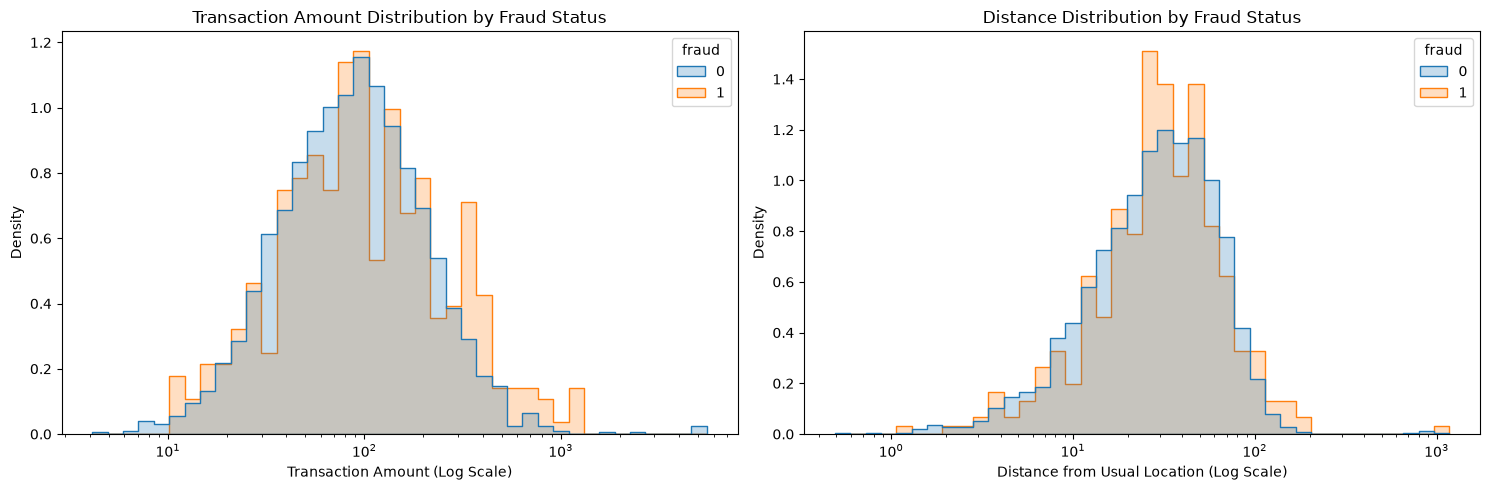

In [45]:
# ============================================================
# Cell 08: Transaction Distribution Analysis
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

# -----------------------------------------
# Plot 01: Transaction Amount Distribution
# -----------------------------------------

sns.histplot(
    data=df,
    x="transaction_amount",
    hue="fraud",
    bins=40,
    element="step",
    stat="density",
    common_norm=False,
    log_scale=True,
    ax=axes[0]
)

axes[0].set_title(
    "Transaction Amount Distribution by Fraud Status"
)

axes[0].set_xlabel(
    "Transaction Amount (Log Scale)"
)

axes[0].set_ylabel(
    "Density"
)

# -----------------------------------------
# Plot 02: Distance Distribution
# -----------------------------------------

sns.histplot(
    data=df,
    x="distance_from_usual_location_km",
    hue="fraud",
    bins=40,
    element="step",
    stat="density",
    common_norm=False,
    log_scale=True,
    ax=axes[1]
)

axes[1].set_title(
    "Distance Distribution by Fraud Status"
)

axes[1].set_xlabel(
    "Distance from Usual Location (Log Scale)"
)

axes[1].set_ylabel(
    "Density"
)

plt.tight_layout()
plt.show()

In [46]:
# ============================================================
# Cell 09: Data Leakage Investigation
# ============================================================

leakage_audit = [
    {
        "feature": "transaction_id",
        "risk": "Identifier / possible ordering proxy",
        "decision": "EXCLUDE",
        "reason": "Not a defensible fraud predictor"
    },
    {
        "feature": "fraud",
        "risk": "Target leakage",
        "decision": "TARGET ONLY",
        "reason": "Must never be included in model inputs"
    },
    {
        "feature": "prior_chargebacks",
        "risk": "Historical information leakage",
        "decision": "VERIFY",
        "reason": "Must include only chargebacks known before transaction"
    },
    {
        "feature": "merchant_risk_score",
        "risk": "Possible post-event information",
        "decision": "VERIFY",
        "reason": "Score must be available at prediction time"
    },
    {
        "feature": "ip_risk_score",
        "risk": "Possible post-event information",
        "decision": "VERIFY",
        "reason": "Score must be computed before authorization"
    },
    {
        "feature": "authentication_level",
        "risk": "Prediction-time availability",
        "decision": "VERIFY",
        "reason": "Must be known before the fraud decision"
    },
    {
        "feature": "distance_from_usual_location_km",
        "risk": "Historical profile leakage",
        "decision": "VERIFY",
        "reason": "Customer profile must use past observations only"
    },
    {
        "feature": "transactions_last_1h",
        "risk": "Future transaction leakage",
        "decision": "VERIFY",
        "reason": "Rolling count must not include future transactions"
    },
    {
        "feature": "transactions_last_24h",
        "risk": "Future transaction leakage",
        "decision": "VERIFY",
        "reason": "Rolling count must not include future transactions"
    }
]

leakage_df = pd.DataFrame(leakage_audit)

print("=" * 70)
print("DATA LEAKAGE AUDIT")
print("=" * 70)

display(leakage_df)

print("\nLeakage Audit Summary:")

display(
    leakage_df["decision"].value_counts()
)

# -----------------------------------------
# Identify excluded model columns
# -----------------------------------------

excluded_columns = [
    "transaction_id",
    "fraud"
]

candidate_feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

print("\nCandidate Feature Count:")
print(len(candidate_feature_columns))

print("\nExcluded Columns:")
print(excluded_columns)

print("\nCandidate Features:")
print(candidate_feature_columns)

print(
    "\nIMPORTANT: VERIFY fields require"
    " prediction-time availability checks."
)

DATA LEAKAGE AUDIT


,feature,risk,decision,reason
0,transaction_id,Identifier / possible ordering proxy,EXCLUDE,Not a defensible fraud predictor
1,fraud,Target leakage,TARGET ONLY,Must never be included in model inputs
2,prior_chargebacks,Historical information leakage,VERIFY,Must include only chargebacks known before tra...
3,merchant_risk_score,Possible post-event information,VERIFY,Score must be available at prediction time
4,ip_risk_score,Possible post-event information,VERIFY,Score must be computed before authorization
5,authentication_level,Prediction-time availability,VERIFY,Must be known before the fraud decision
6,distance_from_usual_location_km,Historical profile leakage,VERIFY,Customer profile must use past observations only
7,transactions_last_1h,Future transaction leakage,VERIFY,Rolling count must not include future transact...
8,transactions_last_24h,Future transaction leakage,VERIFY,Rolling count must not include future transact...



Leakage Audit Summary:


decision
VERIFY         7
EXCLUDE        1
TARGET ONLY    1
Name: count, dtype: int64


Candidate Feature Count:
23

Excluded Columns:
['transaction_id', 'fraud']

Candidate Features:
['hour', 'day_of_week', 'transaction_amount', 'distance_from_usual_location_km', 'transactions_last_1h', 'transactions_last_24h', 'account_age_days', 'failed_logins_24h', 'prior_chargebacks', 'device_age_days', 'merchant_risk_score', 'ip_risk_score', 'email_age_days', 'login_to_transaction_minutes', 'card_presence', 'channel', 'country', 'device_type', 'merchant_category', 'authentication_level', 'new_device', 'billing_address_mismatch', 'customer_tier']

IMPORTANT: VERIFY fields require prediction-time availability checks.


In [47]:
# ============================================================
# SECTION A - DATA FORENSICS
# Cell 10: Final Data Quality Investigation
# ============================================================

print("=" * 70)
print("FINAL DATA QUALITY INVESTIGATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Identify unique transactions containing IQR outliers
# ------------------------------------------------------------

outlier_flags = pd.DataFrame(index=df.index)

for col in outlier_features:

    valid = df[col].dropna()

    q1 = valid.quantile(0.25)
    q3 = valid.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_flags[col] = (
        (df[col] < lower) |
        (df[col] > upper)
    )

any_outlier = outlier_flags.any(axis=1)

unique_outlier_count = int(any_outlier.sum())

print("\nUnique Transactions With Outliers:")
print(unique_outlier_count)

print("\nPercentage of Transactions With Outliers:")
print(round(any_outlier.mean() * 100, 2))

# ------------------------------------------------------------
# 2. Compare fraud rates
# ------------------------------------------------------------

outlier_comparison = (
    df.assign(has_iqr_outlier=any_outlier)
    .groupby("has_iqr_outlier")["fraud"]
    .agg(
        transaction_count="count",
        fraud_count="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

outlier_comparison["fraud_rate"] = (
    outlier_comparison["fraud_rate"] * 100
).round(2)

print("\nFraud Rate Comparison:")

display(outlier_comparison)

# ------------------------------------------------------------
# 3. Categorical feature audit
# ------------------------------------------------------------

categorical_columns = [
    col
    for col in df.select_dtypes(
        include=["object", "string", "category"]
    ).columns
    if col != "transaction_id"
]

categorical_audit = pd.DataFrame({
    "feature": categorical_columns,
    "unique_categories": [
        df[col].nunique(dropna=True)
        for col in categorical_columns
    ],
    "missing_count": [
        df[col].isnull().sum()
        for col in categorical_columns
    ]
})

print("\nCategorical Feature Audit:")

display(categorical_audit)

# ------------------------------------------------------------
# 4. Missing data at transaction level
# ------------------------------------------------------------

transactions_with_missing = (
    df.isnull().any(axis=1).sum()
)

print("\nTransactions With At Least One Missing Value:")
print(transactions_with_missing)

print("\nTransactions Without Missing Values:")
print(len(df) - transactions_with_missing)

print("\nFinal Audit Completed Successfully!")

FINAL DATA QUALITY INVESTIGATION

Unique Transactions With Outliers:
565

Percentage of Transactions With Outliers:
18.83

Fraud Rate Comparison:


,has_iqr_outlier,transaction_count,fraud_count,fraud_rate
0,False,2435,260,10.68
1,True,565,104,18.41



Categorical Feature Audit:


,feature,unique_categories,missing_count
0,card_presence,2,0
1,channel,4,0
2,country,7,0
3,device_type,5,0
4,merchant_category,10,0
5,authentication_level,2,289
6,customer_tier,4,0



Transactions With At Least One Missing Value:
542

Transactions Without Missing Values:
2458

Final Audit Completed Successfully!


In [48]:
# ============================================================
# Cell 11: Generate Data Quality Report
# ============================================================

from pathlib import Path

REPORT_DIR = PROJECT_ROOT / "reports"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

REPORT_PATH = (
    REPORT_DIR / "01_data_quality_report.md"
)

# ------------------------------------------------------------
# Helper: Convert DataFrame to Markdown table
# ------------------------------------------------------------

def dataframe_to_markdown_table(dataframe):

    columns = dataframe.columns.tolist()

    header = "| " + " | ".join(columns) + " |"

    separator = (
        "| " + " | ".join(["---"] * len(columns)) + " |"
    )

    rows = []

    for row in dataframe.itertuples(index=False, name=None):

        values = [
            str(value).replace("|", "\\|")
            for value in row
        ]

        rows.append(
            "| " + " | ".join(values) + " |"
        )

    return "\n".join(
        [header, separator] + rows
    )


# ------------------------------------------------------------
# Generate Report
# ------------------------------------------------------------

report = f"""
# Fraud Risk Intelligence - Data Quality Report

## 1. Dataset Overview

- Total transactions: {len(df)}
- Total columns: {df.shape[1]}
- Fraud transactions: {int(df['fraud'].sum())}
- Legitimate transactions: {int((df['fraud'] == 0).sum())}
- Overall fraud rate: {df['fraud'].mean() * 100:.2f}%
- Total missing cells: {int(df.isnull().sum().sum())}
- Transactions with missing values: {int(df.isnull().any(axis=1).sum())}
- Duplicate records: {int(df.duplicated().sum())}
- Duplicate transaction IDs: {int(df['transaction_id'].duplicated().sum())}

## 2. Missing Data Assessment

{dataframe_to_markdown_table(missingness_df)}

### Findings

Authentication-level missingness is associated with
a higher observed fraud rate.

Missingness may contain predictive information.
However, these relationships are observational
and require validation.

## 3. Invalid Value Assessment

{dataframe_to_markdown_table(invalid_report)}

### Findings

All implemented validation checks passed.

This does not guarantee that the dataset is free
from every possible data-quality issue.

## 4. Outlier Analysis

{dataframe_to_markdown_table(outlier_df)}

### Overall Outlier Comparison

{dataframe_to_markdown_table(outlier_comparison)}

### Findings

Outlier observations may contain useful fraud signals.

No observations have been removed.

The IQR method identifies statistical extremes,
not necessarily erroneous transactions.

## 5. Categorical Feature Audit

{dataframe_to_markdown_table(categorical_audit)}

## 6. Data Leakage Assessment

{dataframe_to_markdown_table(leakage_df)}

### Leakage Decisions

- Exclude transaction_id from predictive features.
- Use fraud only as the target variable.
- Verify point-in-time availability of historical
  and risk-related features before production use.

## 7. Data Treatment Decisions

### Missing Numerical Values

Planned treatment:
Median imputation fitted on training data only.

Missing indicators will be considered where useful.

### Missing Categorical Values

Planned treatment:
Explicit missing category where appropriate.

Authentication-level missingness will be
investigated as a predictive feature.

### Outliers

Planned treatment:
Retain valid extreme observations.

Investigate robust transformations and
model sensitivity to extreme values.

### Categorical Variables

Planned treatment:
Apply appropriate categorical encoding
within the preprocessing pipeline.

### Target Variable

Fraud is the classification target.

It must not appear in the model feature matrix.

### Transaction Identifier

Transaction ID will be excluded from training.

It may be retained separately for transaction
tracking and explanation outputs.

## 8. Validation Strategy

The available dataset does not contain
complete transaction timestamps or customer IDs.

Therefore, a genuine chronological or
customer-grouped split cannot be performed
using the available fields.

A stratified train/validation/test split is
planned, with its limitations documented.

All data-dependent preprocessing will be fitted
inside training or cross-validation pipelines.

The final test set will remain untouched until
the selected model and decision policy are frozen.

## 9. Conclusion

The dataset contains valid transaction records
under the implemented checks, but also includes
missing values and extreme observations.

These observations will be retained during
initial modeling.

Further feature validation, leakage review,
and robustness testing are required before
any production recommendation.
"""

REPORT_PATH.write_text(
    report.strip() + "\n",
    encoding="utf-8"
)

print("=" * 70)
print("DATA QUALITY REPORT GENERATED")
print("=" * 70)

print("Report Location:")
print(REPORT_PATH)

print("\nReport generated successfully!")

DATA QUALITY REPORT GENERATED
Report Location:
e:\fraud-risk-intelligence\fraud-risk-intelligence\reports\01_data_quality_report.md

Report generated successfully!


# Section B — Advanced Exploratory Data Analysis

This section investigates fraud patterns across transaction
attributes, behavioral indicators, risk scores, and feature
interactions.

The analysis focuses on identifying meaningful fraud-risk
patterns and supporting subsequent feature engineering.

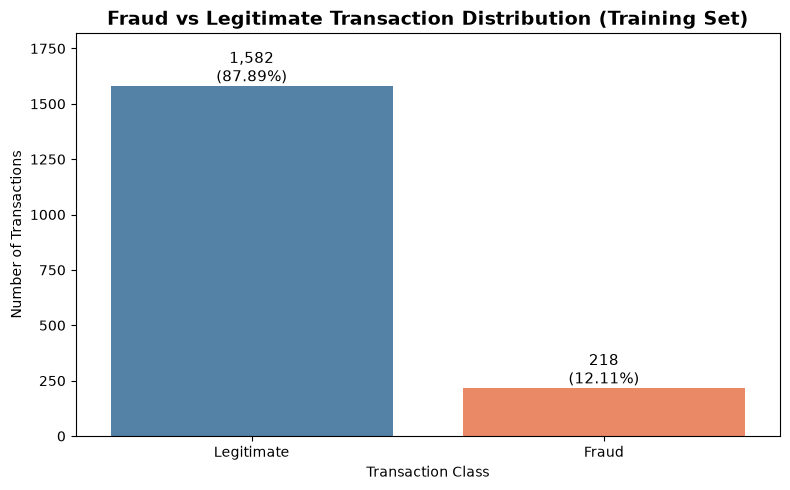

FRAUD CLASS DISTRIBUTION - TRAINING DATASET


,transaction_count,percentage
Legitimate,1582,87.89
Fraud,218,12.11



Total Training Transactions: 1800
Fraud Transactions: 218
Legitimate Transactions: 1582
Fraud Percentage: 12.11%


In [49]:
# ============================================================
# SECTION B - ADVANCED EXPLORATORY DATA ANALYSIS
# Cell 12: Fraud Class Distribution (Training Dataset)
# ============================================================

# ------------------------------------------------------------
# Step 1: Calculate fraud class distribution
# ------------------------------------------------------------

fraud_counts = (
    train_df["fraud"]
    .value_counts()
    .sort_index()
)

fraud_percentages = (
    train_df["fraud"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# ------------------------------------------------------------
# Step 2: Create visualization
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=train_df,
    x="fraud",
    order=[0, 1],
    hue="fraud",
    palette=["steelblue", "coral"],
    legend=False
)

plt.title(
    "Fraud vs Legitimate Transaction Distribution (Training Set)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.xticks(
    ticks=[0, 1],
    labels=["Legitimate", "Fraud"]
)

# ------------------------------------------------------------
# Step 3: Add count and percentage labels
# ------------------------------------------------------------

for i, count in enumerate(fraud_counts):

    percentage = fraud_percentages.iloc[i]

    ax.text(
        i,
        count + 20,
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        fontsize=11
    )

plt.ylim(
    0,
    fraud_counts.max() * 1.15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Step 4: Display summary table
# ------------------------------------------------------------

fraud_distribution_df = pd.DataFrame({
    "transaction_count": fraud_counts,
    "percentage": fraud_percentages.round(2)
})

fraud_distribution_df.index = [
    "Legitimate",
    "Fraud"
]

print("=" * 65)
print("FRAUD CLASS DISTRIBUTION - TRAINING DATASET")
print("=" * 65)

display(fraud_distribution_df)

print("\nTotal Training Transactions:", len(train_df))
print("Fraud Transactions:", int(train_df["fraud"].sum()))
print("Legitimate Transactions:", int((train_df["fraud"] == 0).sum()))

print(
    "Fraud Percentage:",
    f"{train_df['fraud'].mean() * 100:.2f}%"
)

FRAUD ANALYSIS BY TRANSACTION CHANNEL - TRAINING SET


,channel,total_transactions,fraud_transactions,fraud_rate
0,E-commerce,709,100,14.10
1,Mobile App,347,45,12.97
2,ATM,163,16,9.82
3,POS,581,57,9.81


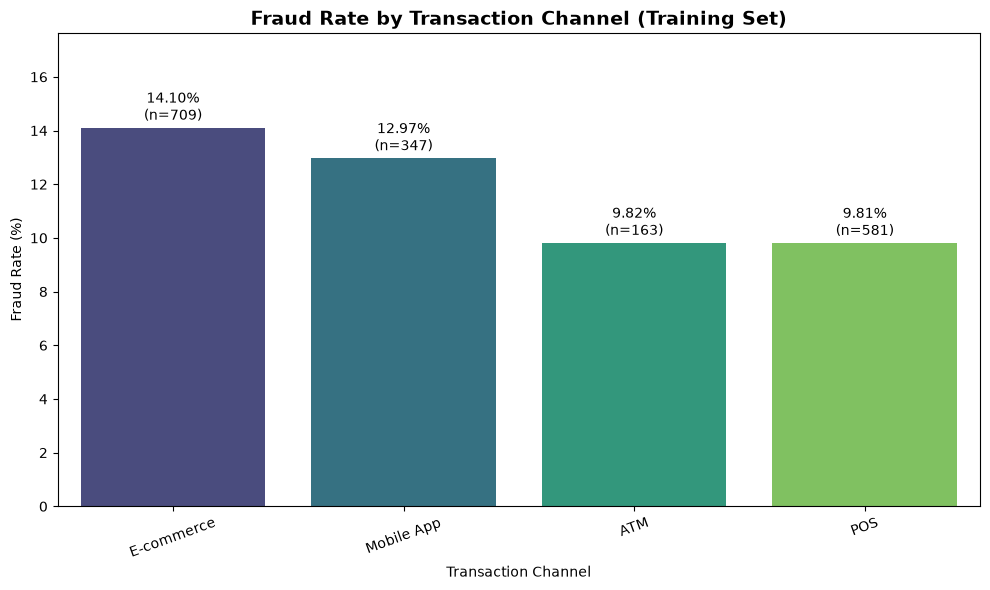


Highest Fraud Rate Channel:
E-commerce - 14.10%

Lowest Fraud Rate Channel:
POS - 9.81%

Overall Training Fraud Rate:
12.11%


In [50]:
# ============================================================
# SECTION B - ADVANCED EXPLORATORY DATA ANALYSIS
# Cell 13: Fraud Rate by Transaction Channel (Training Dataset)
# ============================================================

# ------------------------------------------------------------
# Step 1: Calculate fraud rate by channel
# ------------------------------------------------------------

channel_analysis = (
    train_df.groupby("channel")["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

# Convert fraud rate to percentage
channel_analysis["fraud_rate"] = (
    channel_analysis["fraud_rate"] * 100
)

# Sort channels by fraud rate
channel_analysis = channel_analysis.sort_values(
    by="fraud_rate",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Step 2: Display summary table
# ------------------------------------------------------------

print("=" * 65)
print("FRAUD ANALYSIS BY TRANSACTION CHANNEL - TRAINING SET")
print("=" * 65)

display(channel_analysis.round(2))

# ------------------------------------------------------------
# Step 3: Create visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=channel_analysis,
    x="channel",
    y="fraud_rate",
    hue="channel",
    palette="viridis",
    legend=False
)

plt.title(
    "Fraud Rate by Transaction Channel (Training Set)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Transaction Channel")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=20)

# ------------------------------------------------------------
# Step 4: Add fraud rate and transaction count labels
# ------------------------------------------------------------

for i, row in enumerate(channel_analysis.itertuples()):

    ax.text(
        i,
        row.fraud_rate + 0.3,
        f"{row.fraud_rate:.2f}%\n(n={row.total_transactions})",
        ha="center",
        fontsize=10
    )

plt.ylim(
    0,
    max(1, channel_analysis["fraud_rate"].max() * 1.25)
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Step 5: Display additional analysis
# ------------------------------------------------------------

print("\nHighest Fraud Rate Channel:")

highest_risk_channel = channel_analysis.iloc[0]

print(
    f"{highest_risk_channel['channel']} - "
    f"{highest_risk_channel['fraud_rate']:.2f}%"
)

print("\nLowest Fraud Rate Channel:")

lowest_risk_channel = channel_analysis.iloc[-1]

print(
    f"{lowest_risk_channel['channel']} - "
    f"{lowest_risk_channel['fraud_rate']:.2f}%"
)

print("\nOverall Training Fraud Rate:")

print(
    f"{train_df['fraud'].mean() * 100:.2f}%"
)

## Data Splitting for Leakage-Safe Analysis

The dataset is divided into training, validation,
and testing subsets using stratified random sampling.

The final test set is reserved for final evaluation.

Feature exploration and selection will primarily
use the training set.

Because complete transaction timestamps and customer
identifiers are unavailable, chronological and
customer-grouped validation cannot be implemented.

In [51]:
# ============================================================
# Cell 14: Train / Validation / Test Split
# ============================================================

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# ------------------------------------------------------------
# Step 1: Separate training and temporary datasets
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=df["fraud"]
)

# ------------------------------------------------------------
# Step 2: Split temporary dataset into validation and test
# ------------------------------------------------------------

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=temp_df["fraud"]
)

# ------------------------------------------------------------
# Step 3: Verify dataset sizes
# ------------------------------------------------------------

split_summary = pd.DataFrame({
    "dataset": ["Training", "Validation", "Testing"],
    "total_transactions": [
        len(train_df),
        len(val_df),
        len(test_df)
    ],
    "fraud_count": [
        train_df["fraud"].sum(),
        val_df["fraud"].sum(),
        test_df["fraud"].sum()
    ],
    "fraud_rate": [
        train_df["fraud"].mean() * 100,
        val_df["fraud"].mean() * 100,
        test_df["fraud"].mean() * 100
    ]
})

print("=" * 65)
print("DATASET SPLIT SUMMARY")
print("=" * 65)

display(split_summary.round(2))

# ------------------------------------------------------------
# Step 4: Verify no index overlap
# ------------------------------------------------------------

assert set(train_df.index).isdisjoint(val_df.index)

assert set(train_df.index).isdisjoint(test_df.index)

assert set(val_df.index).isdisjoint(test_df.index)

assert (
    len(train_df) + len(val_df) + len(test_df)
) == len(df)

print("\nAll split integrity checks passed!")

print("\nTraining Shape:", train_df.shape)
print("Validation Shape:", val_df.shape)
print("Testing Shape:", test_df.shape)

DATASET SPLIT SUMMARY


,dataset,total_transactions,fraud_count,fraud_rate
0,Training,1800,218,12.11
1,Validation,600,73,12.17
2,Testing,600,73,12.17



All split integrity checks passed!

Training Shape: (1800, 25)
Validation Shape: (600, 25)
Testing Shape: (600, 25)


FRAUD RATE BY MERCHANT CATEGORY


,merchant_category,total_transactions,fraud_transactions,fraud_rate
7,Jewelry,63,16,25.40
2,Fashion,234,40,17.09
4,Gaming,147,24,16.33
8,Restaurants,245,31,12.65
6,Healthcare,132,16,12.12
9,Travel,134,16,11.94
1,Electronics,195,22,11.28
5,Grocery,292,25,8.56
0,Digital Services,188,16,8.51
3,Fuel,170,12,7.06


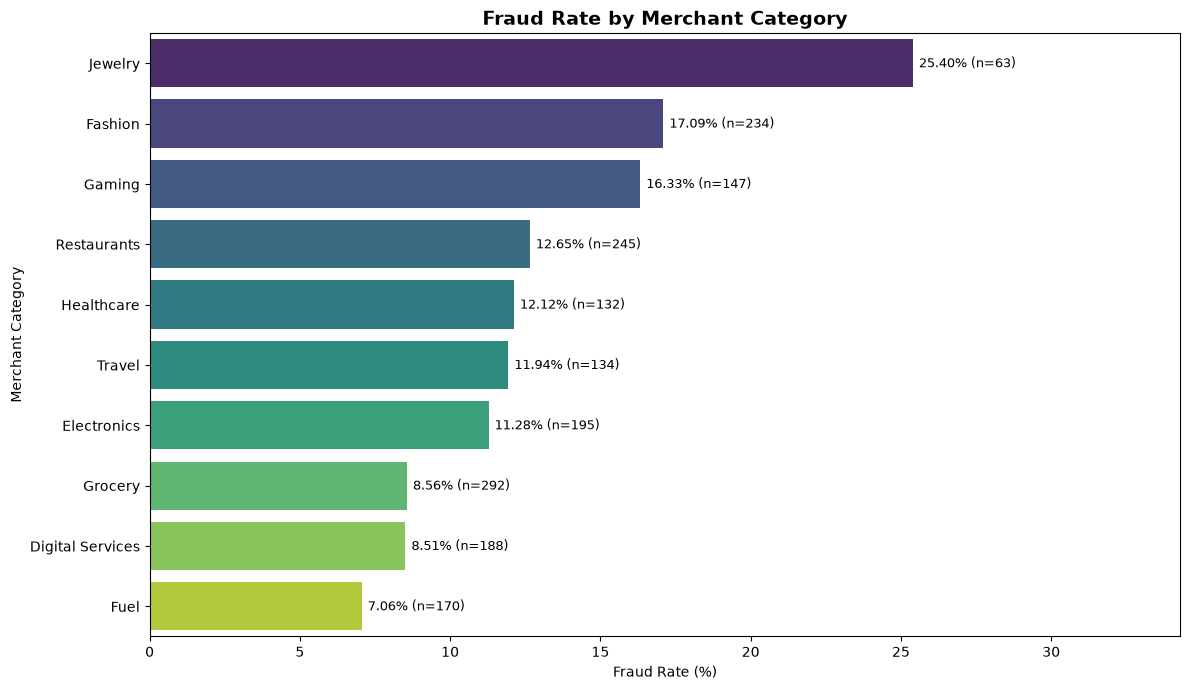

In [52]:
# ============================================================
# SECTION B - ADVANCED EDA
# Cell 15: Fraud Rate by Merchant Category
# ============================================================

merchant_analysis = (
    train_df.groupby("merchant_category")["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

merchant_analysis["fraud_rate"] *= 100

merchant_analysis = merchant_analysis.sort_values(
    by="fraud_rate",
    ascending=False
)

print("=" * 65)
print("FRAUD RATE BY MERCHANT CATEGORY")
print("=" * 65)

display(merchant_analysis.round(2))

# Visualization

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=merchant_analysis,
    x="fraud_rate",
    y="merchant_category",
    hue="merchant_category",
    palette="viridis",
    legend=False
)

plt.title(
    "Fraud Rate by Merchant Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Fraud Rate (%)")
plt.ylabel("Merchant Category")

for i, row in enumerate(merchant_analysis.itertuples()):

    ax.text(
        row.fraud_rate + 0.2,
        i,
        f"{row.fraud_rate:.2f}% (n={row.total_transactions})",
        va="center",
        fontsize=9
    )

plt.xlim(
    0,
    merchant_analysis["fraud_rate"].max() * 1.35
)

plt.tight_layout()
plt.show()

FRAUD RATE BY AUTHENTICATION LEVEL


,authentication_level,total_transactions,fraud_transactions,fraud_rate
0,Missing,161,33,20.50
1,Standard,819,100,12.21
2,Strong,820,85,10.37


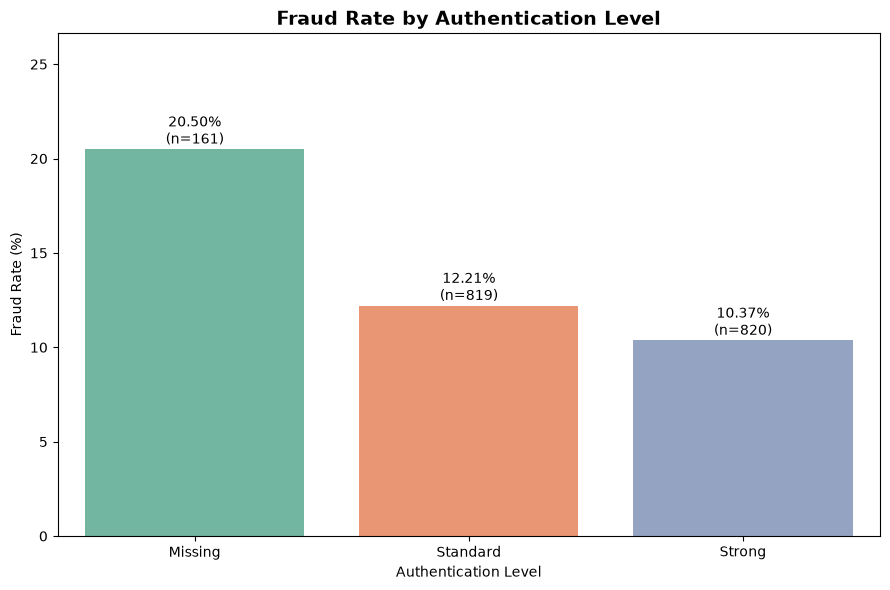

In [53]:
# ============================================================
# Cell 16: Fraud Rate by Authentication Level
# ============================================================

# Create a temporary copy for analysis
auth_df = train_df.copy()

# Preserve missingness as a separate category
auth_df["authentication_level"] = (
    auth_df["authentication_level"]
    .fillna("Missing")
)

# Group analysis
auth_analysis = (
    auth_df.groupby("authentication_level")["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

auth_analysis["fraud_rate"] *= 100

auth_analysis = auth_analysis.sort_values(
    "fraud_rate",
    ascending=False
)

print("=" * 65)
print("FRAUD RATE BY AUTHENTICATION LEVEL")
print("=" * 65)

display(auth_analysis.round(2))

# Visualization

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    data=auth_analysis,
    x="authentication_level",
    y="fraud_rate",
    hue="authentication_level",
    palette="Set2",
    legend=False
)

plt.title(
    "Fraud Rate by Authentication Level",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Authentication Level")
plt.ylabel("Fraud Rate (%)")

for i, row in enumerate(auth_analysis.itertuples()):

    ax.text(
        i,
        row.fraud_rate + 0.3,
        f"{row.fraud_rate:.2f}%\n(n={row.total_transactions})",
        ha="center",
        fontsize=10
    )

plt.ylim(
    0,
    auth_analysis["fraud_rate"].max() * 1.30
)

plt.tight_layout()
plt.show()

FRAUD RATE BY CUSTOMER TIER


,customer_tier,total_transactions,fraud_transactions,fraud_rate
0,Platinum,173,26,15.03
1,Basic,663,90,13.57
2,Gold,406,44,10.84
3,Silver,558,58,10.39


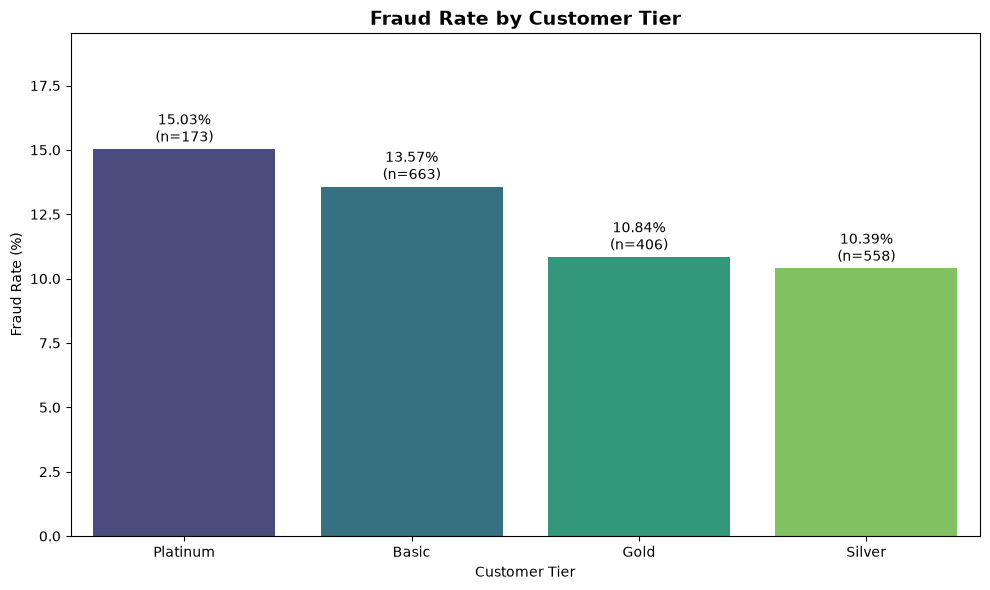

In [54]:
# ============================================================
# SECTION B - ADVANCED EDA
# Cell 17: Fraud Rate by Customer Tier
# ============================================================

# Reusable fraud-rate analysis function

def fraud_rate_summary(data, feature):

    result = (
        data.groupby(feature, dropna=False)["fraud"]
        .agg(
            total_transactions="count",
            fraud_transactions="sum",
            fraud_rate="mean"
        )
        .reset_index()
    )

    result["fraud_rate"] *= 100

    return result.sort_values(
        "fraud_rate",
        ascending=False
    ).reset_index(drop=True)


# Customer tier analysis

tier_analysis = fraud_rate_summary(
    train_df,
    "customer_tier"
)

print("=" * 65)
print("FRAUD RATE BY CUSTOMER TIER")
print("=" * 65)

display(tier_analysis.round(2))


# Visualization

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=tier_analysis,
    x="customer_tier",
    y="fraud_rate",
    hue="customer_tier",
    palette="viridis",
    legend=False
)

plt.title(
    "Fraud Rate by Customer Tier",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Customer Tier")
plt.ylabel("Fraud Rate (%)")

for i, row in enumerate(tier_analysis.itertuples()):

    ax.text(
        i,
        row.fraud_rate + 0.3,
        f"{row.fraud_rate:.2f}%\n(n={row.total_transactions})",
        ha="center",
        fontsize=10
    )

plt.ylim(
    0,
    max(1, tier_analysis["fraud_rate"].max() * 1.30)
)

plt.tight_layout()
plt.show()

FRAUD RATE BY DEVICE TYPE


,device_type,total_transactions,fraud_transactions,fraud_rate
0,iOS,522,66,12.64
1,Android,700,86,12.29
2,macOS,197,24,12.18
3,Windows,217,24,11.06
4,Other,164,18,10.98


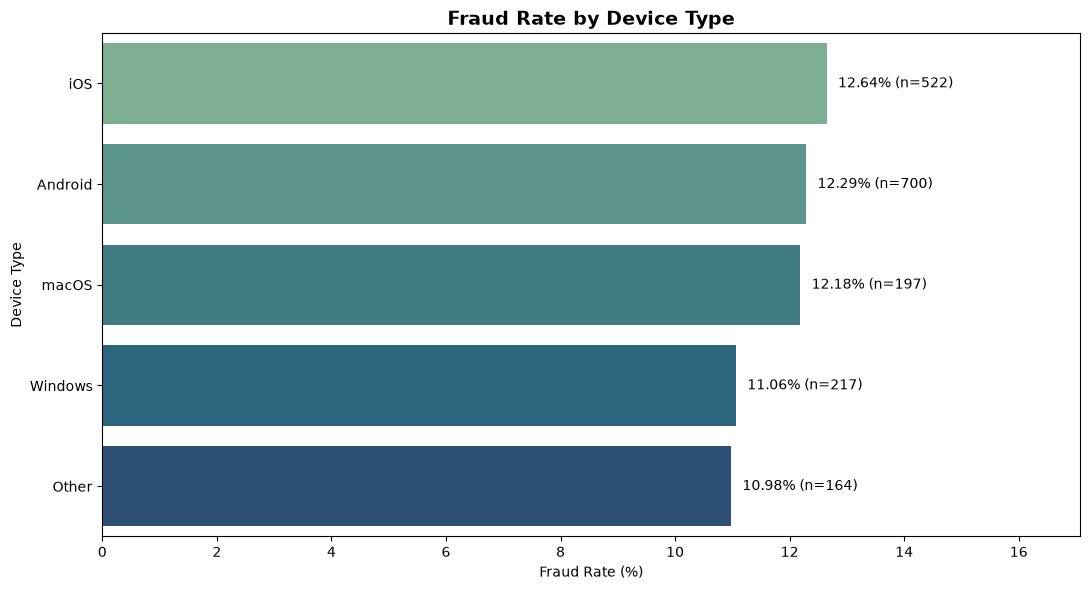

In [55]:
# ============================================================
# Cell 18: Fraud Rate by Device Type
# ============================================================

device_analysis = fraud_rate_summary(
    train_df,
    "device_type"
)

print("=" * 65)
print("FRAUD RATE BY DEVICE TYPE")
print("=" * 65)

display(device_analysis.round(2))


# Visualization

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=device_analysis,
    x="fraud_rate",
    y="device_type",
    hue="device_type",
    palette="crest",
    legend=False
)

plt.title(
    "Fraud Rate by Device Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Fraud Rate (%)")
plt.ylabel("Device Type")

for i, row in enumerate(device_analysis.itertuples()):

    ax.text(
        row.fraud_rate + 0.2,
        i,
        f"{row.fraud_rate:.2f}% (n={row.total_transactions})",
        va="center",
        fontsize=10
    )

plt.xlim(
    0,
    max(1, device_analysis["fraud_rate"].max() * 1.35)
)

plt.tight_layout()
plt.show()

FRAUD RATE BY HOUR


,hour,total_transactions,fraud_transactions,fraud_rate
3,0,68,11,16.18
13,1,84,9,10.71
20,2,71,6,8.45
9,3,81,10,12.35
1,4,65,11,16.92
23,5,63,4,6.35
0,6,68,14,20.59
12,7,92,10,10.87
18,8,76,7,9.21
17,9,63,6,9.52



FRAUD RATE BY DAY OF WEEK


,day_of_week,total_transactions,fraud_transactions,fraud_rate
6,0,223,19,8.52
0,1,299,48,16.05
2,2,273,36,13.19
4,3,245,26,10.61
3,4,269,29,10.78
5,5,244,25,10.25
1,6,247,35,14.17


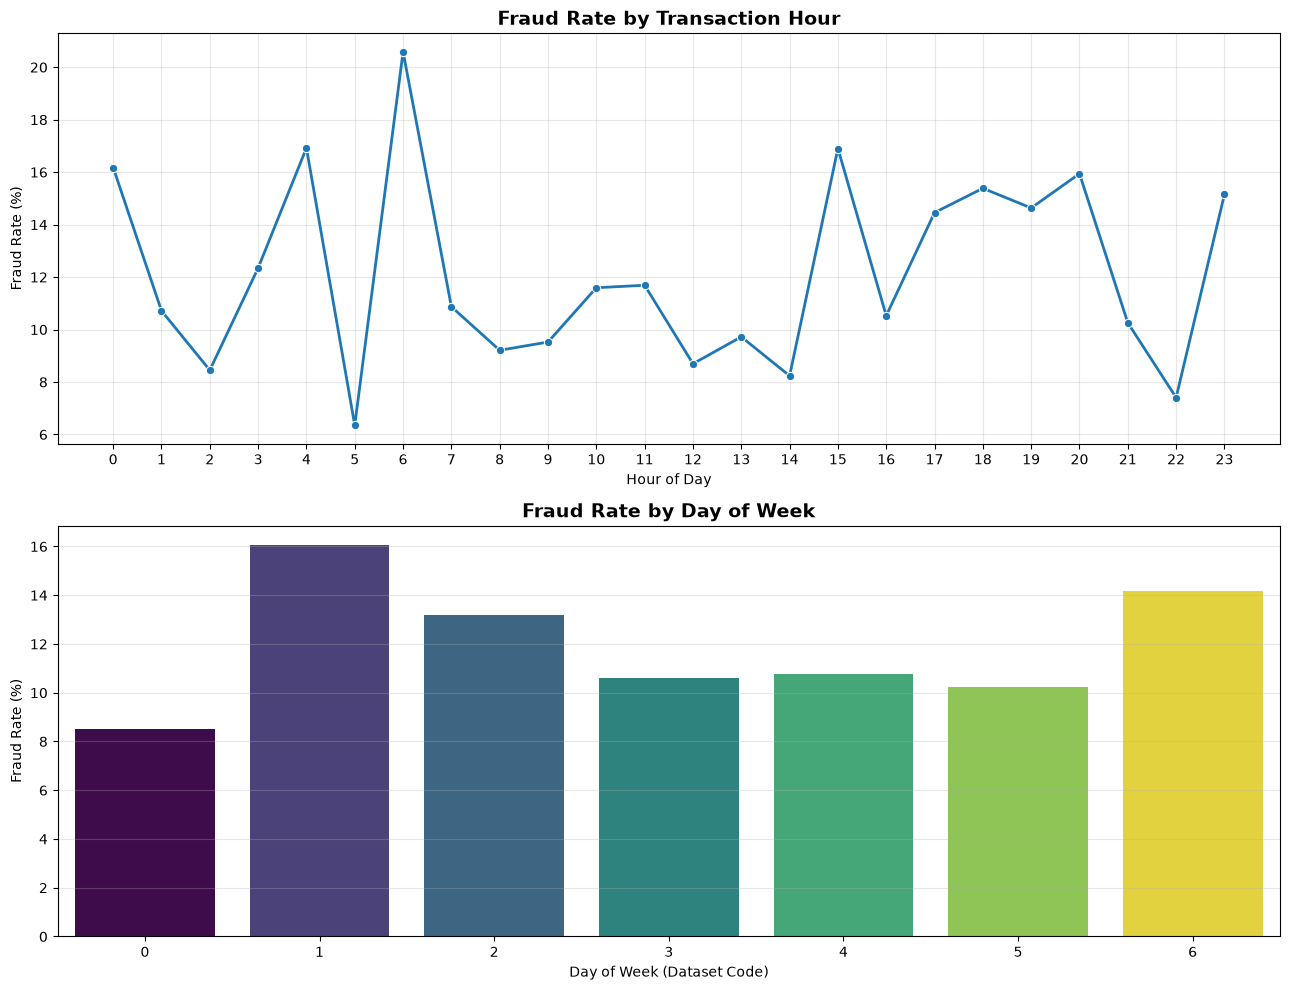

In [56]:
# ============================================================
# Cell 19: Fraud Rate by Hour and Day of Week
# ============================================================

# Hourly fraud analysis

hour_analysis = fraud_rate_summary(
    train_df,
    "hour"
).sort_values("hour")


# Day-of-week fraud analysis

day_analysis = fraud_rate_summary(
    train_df,
    "day_of_week"
).sort_values("day_of_week")


print("=" * 65)
print("FRAUD RATE BY HOUR")
print("=" * 65)

display(hour_analysis.round(2))


print("\n" + "=" * 65)
print("FRAUD RATE BY DAY OF WEEK")
print("=" * 65)

display(day_analysis.round(2))


# ============================================================
# Visualizations
# ============================================================

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 10)
)

# ------------------------------------------------------------
# Plot 01: Hourly Fraud Rate
# ------------------------------------------------------------

sns.lineplot(
    data=hour_analysis,
    x="hour",
    y="fraud_rate",
    marker="o",
    linewidth=2,
    ax=axes[0]
)

axes[0].set_title(
    "Fraud Rate by Transaction Hour",
    fontsize=14,
    fontweight="bold"
)

axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Fraud Rate (%)")

axes[0].set_xticks(range(24))

axes[0].grid(
    True,
    alpha=0.3
)


# ------------------------------------------------------------
# Plot 02: Fraud Rate by Day of Week
# ------------------------------------------------------------

sns.barplot(
    data=day_analysis,
    x="day_of_week",
    y="fraud_rate",
    hue="day_of_week",
    palette="viridis",
    legend=False,
    ax=axes[1]
)

axes[1].set_title(
    "Fraud Rate by Day of Week",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Day of Week (Dataset Code)")
axes[1].set_ylabel("Fraud Rate (%)")

axes[1].grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

FRAUD RATE BY TRANSACTION AMOUNT


,amount_range,total_transactions,fraud_transactions,fraud_rate
0,"(4.119, 43.89]",354,41,11.58
1,"(43.89, 72.514]",353,33,9.35
2,"(72.514, 109.364]",354,44,12.43
3,"(109.364, 182.384]",353,38,10.76
4,"(182.384, 5502.776]",354,60,16.95


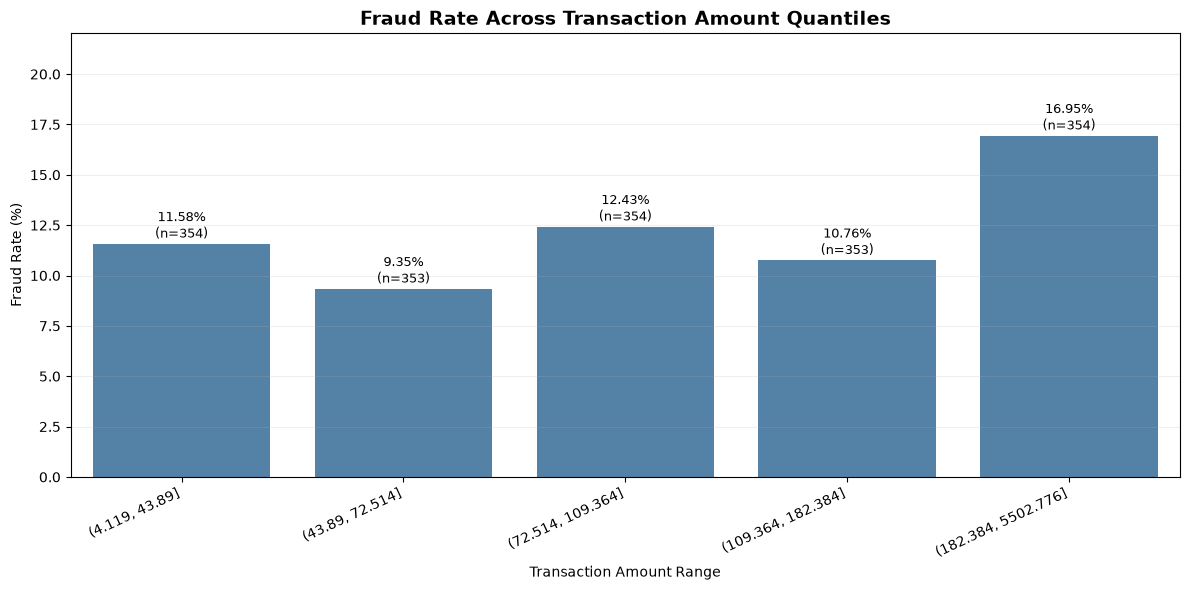

In [57]:
# ============================================================
# SECTION B - ADVANCED EDA
# Cell 20: Transaction Amount vs Fraud Rate
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare training data
# ------------------------------------------------------------

amount_df = train_df[
    ["transaction_amount", "fraud"]
].dropna().copy()

# ------------------------------------------------------------
# Step 2: Create quantile-based transaction amount bins
# ------------------------------------------------------------

amount_df["amount_bin"] = pd.qcut(
    amount_df["transaction_amount"],
    q=5,
    duplicates="drop"
)

# ------------------------------------------------------------
# Step 3: Calculate fraud statistics
# ------------------------------------------------------------

amount_analysis = (
    amount_df.groupby(
        "amount_bin",
        observed=True
    )["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

amount_analysis["fraud_rate"] *= 100

amount_analysis["amount_range"] = (
    amount_analysis["amount_bin"].astype(str)
)

print("=" * 65)
print("FRAUD RATE BY TRANSACTION AMOUNT")
print("=" * 65)

display(
    amount_analysis[
        [
            "amount_range",
            "total_transactions",
            "fraud_transactions",
            "fraud_rate"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# Step 4: Visualization
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=amount_analysis,
    x="amount_range",
    y="fraud_rate",
    color="steelblue"
)

plt.title(
    "Fraud Rate Across Transaction Amount Quantiles",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Transaction Amount Range")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=25, ha="right")

for i, row in enumerate(amount_analysis.itertuples()):

    ax.text(
        i,
        row.fraud_rate + 0.3,
        f"{row.fraud_rate:.2f}%\n(n={row.total_transactions})",
        ha="center",
        fontsize=9
    )

plt.ylim(
    0,
    max(1, amount_analysis["fraud_rate"].max() * 1.30)
)

plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

FRAUD RATE BY TRANSACTION VELOCITY


,velocity_group,total_transactions,fraud_transactions,fraud_rate
0,0,197,18,9.14
1,1,432,35,8.10
2,2,508,61,12.01
3,3-4,541,83,15.34
4,5-6,111,16,14.41
5,7+,11,5,45.45


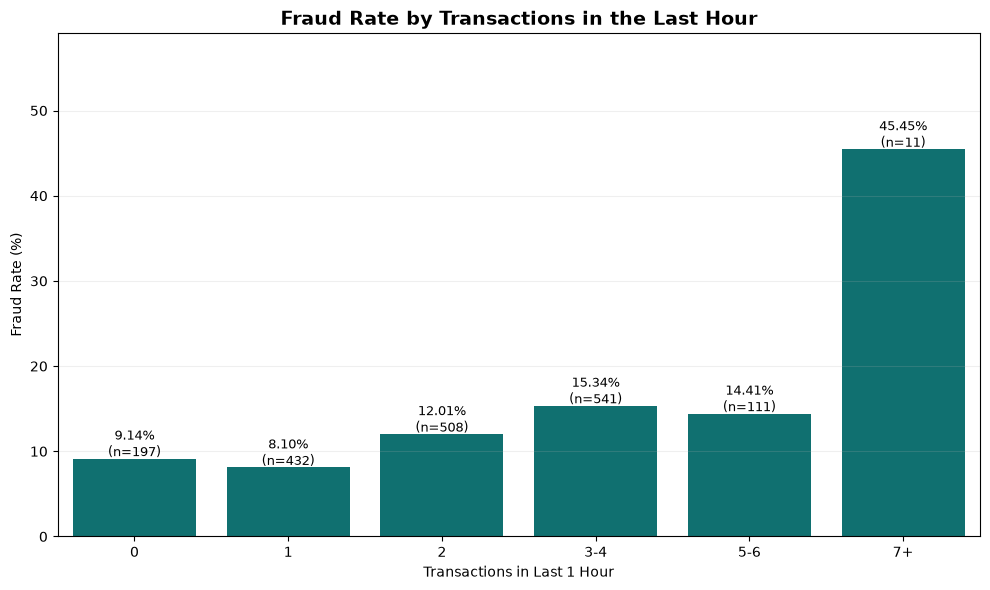

In [58]:
# ============================================================
# Cell 21: Transaction Velocity vs Fraud Rate
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare training data
# ------------------------------------------------------------

velocity_df = train_df[
    ["transactions_last_1h", "fraud"]
].dropna().copy()

# ------------------------------------------------------------
# Step 2: Create velocity groups
# ------------------------------------------------------------

velocity_df["velocity_group"] = pd.cut(
    velocity_df["transactions_last_1h"],
    bins=[-0.1, 0.5, 1.5, 2.5, 4.5, 6.5, np.inf],
    labels=[
        "0",
        "1",
        "2",
        "3-4",
        "5-6",
        "7+"
    ]
)

# ------------------------------------------------------------
# Step 3: Calculate fraud rates
# ------------------------------------------------------------

velocity_analysis = (
    velocity_df.groupby(
        "velocity_group",
        observed=True
    )["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

velocity_analysis["fraud_rate"] *= 100

print("=" * 65)
print("FRAUD RATE BY TRANSACTION VELOCITY")
print("=" * 65)

display(velocity_analysis.round(2))

# ------------------------------------------------------------
# Step 4: Visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=velocity_analysis,
    x="velocity_group",
    y="fraud_rate",
    color="teal"
)

plt.title(
    "Fraud Rate by Transactions in the Last Hour",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Transactions in Last 1 Hour")
plt.ylabel("Fraud Rate (%)")

for i, row in enumerate(velocity_analysis.itertuples()):

    ax.text(
        i,
        row.fraud_rate + 0.3,
        f"{row.fraud_rate:.2f}%\n(n={row.total_transactions})",
        ha="center",
        fontsize=9
    )

plt.ylim(
    0,
    max(1, velocity_analysis["fraud_rate"].max() * 1.30)
)

plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

FRAUD RATE BY DISTANCE FROM USUAL LOCATION


,distance_range,total_transactions,fraud_transactions,fraud_rate
0,"(0.489, 14.192]",352,40,11.36
1,"(14.192, 24.278]",351,39,11.11
2,"(24.278, 35.642]",351,51,14.53
3,"(35.642, 54.728]",351,45,12.82
4,"(54.728, 1173.269]",352,39,11.08


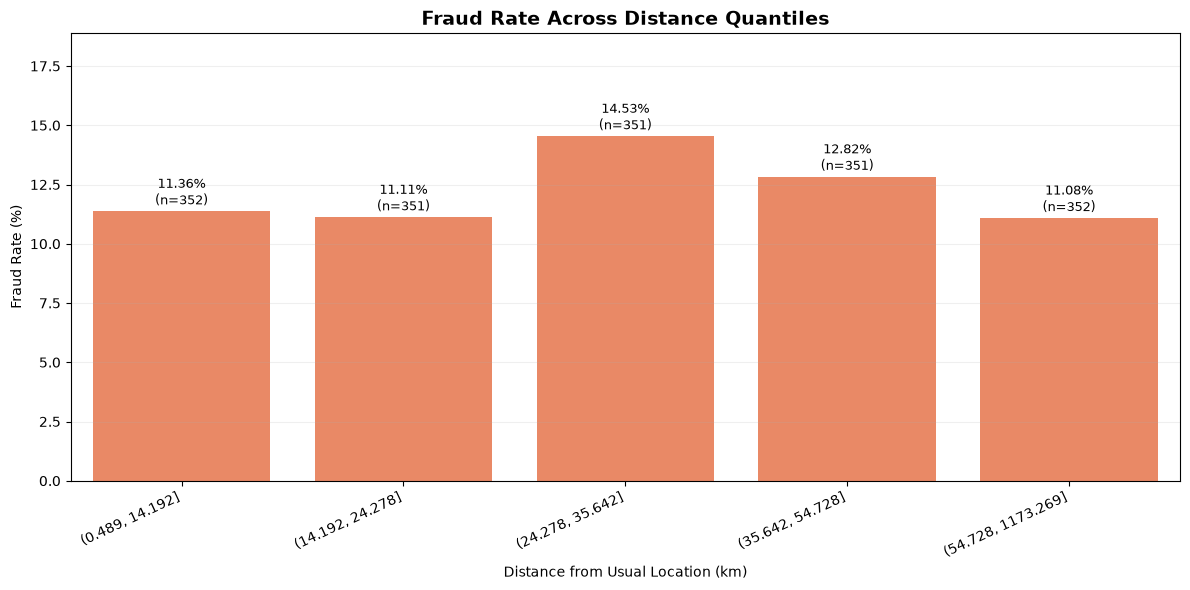

In [59]:
# ============================================================
# Cell 22: Distance vs Fraud Rate
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare training data
# ------------------------------------------------------------

distance_df = train_df[
    ["distance_from_usual_location_km", "fraud"]
].dropna().copy()

# ------------------------------------------------------------
# Step 2: Create distance quantile groups
# ------------------------------------------------------------

distance_df["distance_bin"] = pd.qcut(
    distance_df["distance_from_usual_location_km"],
    q=5,
    duplicates="drop"
)

# ------------------------------------------------------------
# Step 3: Calculate fraud statistics
# ------------------------------------------------------------

distance_analysis = (
    distance_df.groupby(
        "distance_bin",
        observed=True
    )["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

distance_analysis["fraud_rate"] *= 100

distance_analysis["distance_range"] = (
    distance_analysis["distance_bin"].astype(str)
)

print("=" * 65)
print("FRAUD RATE BY DISTANCE FROM USUAL LOCATION")
print("=" * 65)

display(
    distance_analysis[
        [
            "distance_range",
            "total_transactions",
            "fraud_transactions",
            "fraud_rate"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# Step 4: Visualization
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=distance_analysis,
    x="distance_range",
    y="fraud_rate",
    color="coral"
)

plt.title(
    "Fraud Rate Across Distance Quantiles",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Distance from Usual Location (km)")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=25, ha="right")

for i, row in enumerate(distance_analysis.itertuples()):

    ax.text(
        i,
        row.fraud_rate + 0.3,
        f"{row.fraud_rate:.2f}%\n(n={row.total_transactions})",
        ha="center",
        fontsize=9
    )

plt.ylim(
    0,
    max(1, distance_analysis["fraud_rate"].max() * 1.30)
)

plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

FRAUD RATE BY ACCOUNT AGE


,account_age_range,total_transactions,fraud_transactions,fraud_rate
0,"(0.999, 336.0]",361,50,13.85
1,"(336.0, 688.6]",359,45,12.53
2,"(688.6, 1045.6]",360,50,13.89
3,"(1045.6, 1409.0]",360,40,11.11
4,"(1409.0, 1795.0]",360,33,9.17


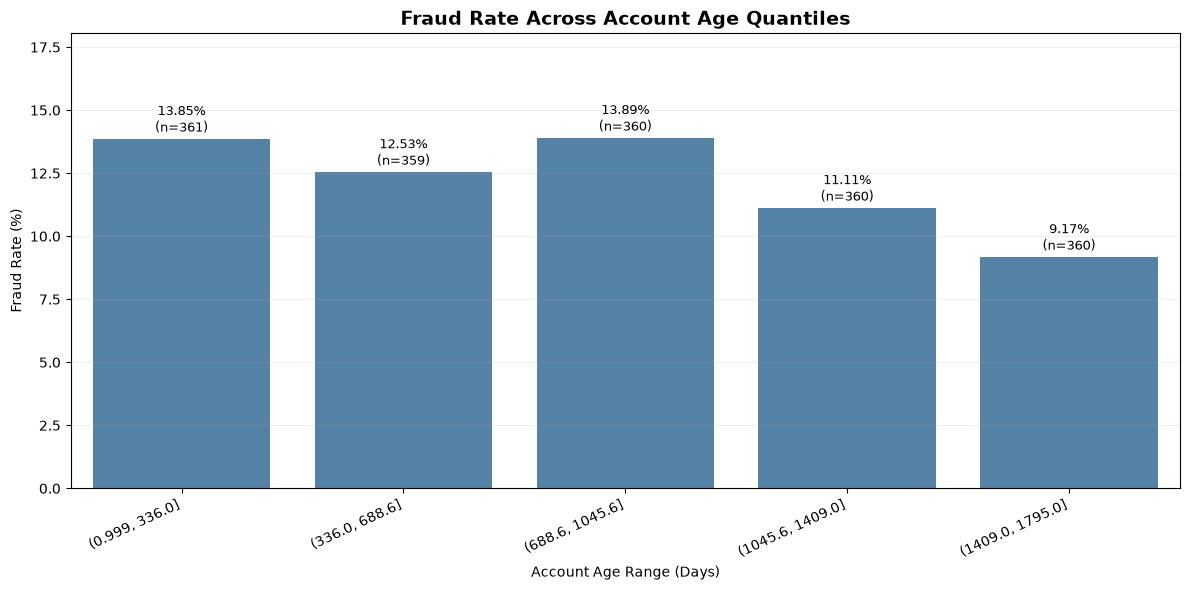

In [60]:
# ============================================================
# SECTION B - ADVANCED EDA
# Cell 23: Account Age vs Fraud Rate
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare training data
# ------------------------------------------------------------

account_df = train_df[
    ["account_age_days", "fraud"]
].dropna().copy()

# ------------------------------------------------------------
# Step 2: Create account age quantile groups
# ------------------------------------------------------------

account_df["account_age_bin"] = pd.qcut(
    account_df["account_age_days"],
    q=5,
    duplicates="drop"
)

# ------------------------------------------------------------
# Step 3: Calculate fraud statistics
# ------------------------------------------------------------

account_age_analysis = (
    account_df.groupby(
        "account_age_bin",
        observed=True
    )["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

account_age_analysis["fraud_rate"] *= 100

account_age_analysis["account_age_range"] = (
    account_age_analysis["account_age_bin"].astype(str)
)

# ------------------------------------------------------------
# Step 4: Display results
# ------------------------------------------------------------

print("=" * 65)
print("FRAUD RATE BY ACCOUNT AGE")
print("=" * 65)

display(
    account_age_analysis[
        [
            "account_age_range",
            "total_transactions",
            "fraud_transactions",
            "fraud_rate"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# Step 5: Visualization
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=account_age_analysis,
    x="account_age_range",
    y="fraud_rate",
    color="steelblue"
)

plt.title(
    "Fraud Rate Across Account Age Quantiles",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Account Age Range (Days)")
plt.ylabel("Fraud Rate (%)")

plt.xticks(rotation=25, ha="right")

for i, row in enumerate(account_age_analysis.itertuples()):

    ax.text(
        i,
        row.fraud_rate + 0.3,
        f"{row.fraud_rate:.2f}%\n(n={row.total_transactions})",
        ha="center",
        fontsize=9
    )

plt.ylim(
    0,
    max(1, account_age_analysis["fraud_rate"].max() * 1.30)
)

plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

FRAUD RATE BY MERCHANT_RISK_SCORE


,risk_range,total_transactions,fraud_transactions,fraud_rate
0,"(0.008, 0.159]",356,40,11.24
1,"(0.159, 0.246]",355,34,9.58
2,"(0.246, 0.324]",351,42,11.97
3,"(0.324, 0.429]",351,47,13.39
4,"(0.429, 0.818]",354,55,15.54


FRAUD RATE BY IP_RISK_SCORE


,risk_range,total_transactions,fraud_transactions,fraud_rate
0,"(0.003, 0.1]",358,40,11.17
1,"(0.1, 0.174]",355,37,10.42
2,"(0.174, 0.24]",359,37,10.31
3,"(0.24, 0.343]",352,43,12.22
4,"(0.343, 0.738]",355,58,16.34


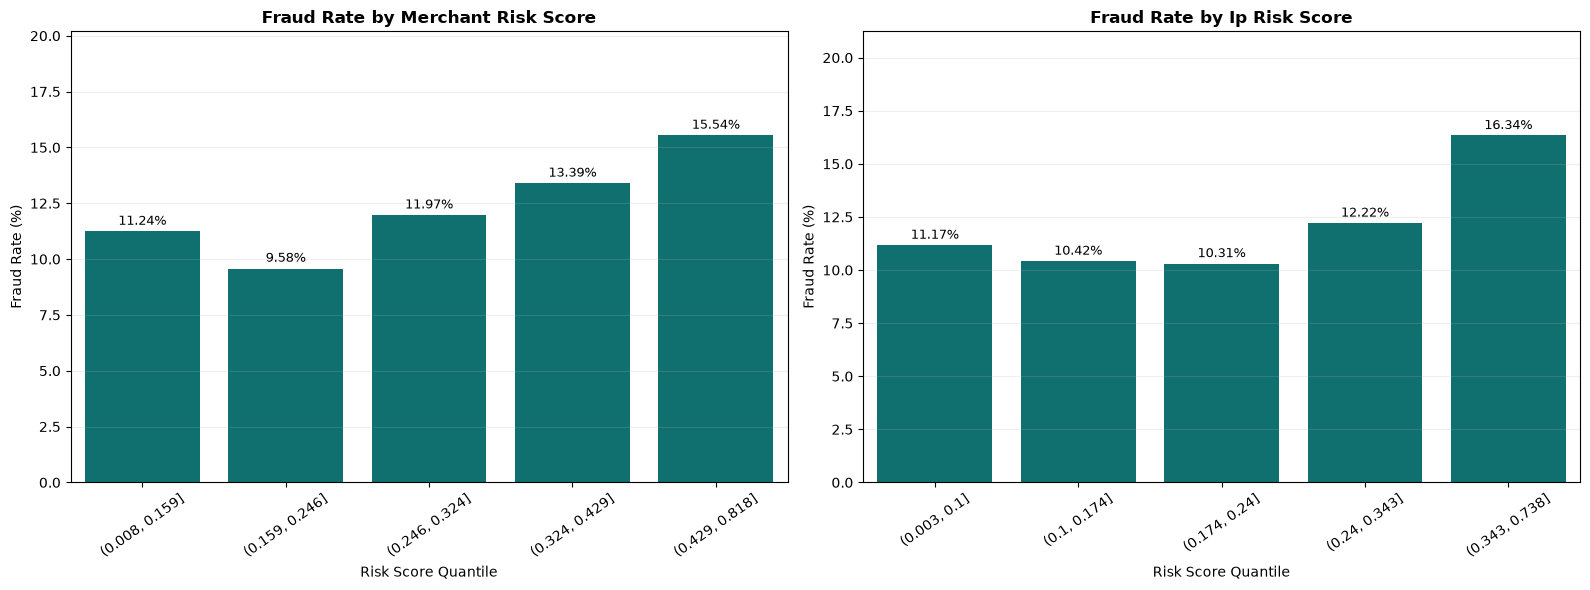

In [61]:
# ============================================================
# SECTION B - ADVANCED EDA
# Cell 24: Merchant Risk and IP Risk Analysis
# ============================================================

risk_features = [
    "merchant_risk_score",
    "ip_risk_score"
]

risk_analysis_results = {}

# ------------------------------------------------------------
# Step 1: Calculate fraud rates across risk quantiles
# ------------------------------------------------------------

for feature in risk_features:

    risk_df = train_df[
        [feature, "fraud"]
    ].dropna().copy()

    risk_df["risk_bin"] = pd.qcut(
        risk_df[feature],
        q=5,
        duplicates="drop"
    )

    analysis = (
        risk_df.groupby(
            "risk_bin",
            observed=True
        )["fraud"]
        .agg(
            total_transactions="count",
            fraud_transactions="sum",
            fraud_rate="mean"
        )
        .reset_index()
    )

    analysis["fraud_rate"] *= 100

    analysis["risk_range"] = (
        analysis["risk_bin"].astype(str)
    )

    risk_analysis_results[feature] = analysis

    print("=" * 65)
    print(f"FRAUD RATE BY {feature.upper()}")
    print("=" * 65)

    display(
        analysis[
            [
                "risk_range",
                "total_transactions",
                "fraud_transactions",
                "fraud_rate"
            ]
        ].round(2)
    )

# ------------------------------------------------------------
# Step 2: Visualizations
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for i, feature in enumerate(risk_features):

    analysis = risk_analysis_results[feature]

    sns.barplot(
        data=analysis,
        x="risk_range",
        y="fraud_rate",
        color="teal",
        ax=axes[i]
    )

    axes[i].set_title(
        f"Fraud Rate by {feature.replace('_', ' ').title()}",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel("Risk Score Quantile")
    axes[i].set_ylabel("Fraud Rate (%)")

    axes[i].tick_params(
        axis="x",
        rotation=35
    )

    axes[i].set_ylim(
        0,
        max(1, analysis["fraud_rate"].max() * 1.30)
    )

    for j, row in enumerate(analysis.itertuples()):

        axes[i].text(
            j,
            row.fraud_rate + 0.3,
            f"{row.fraud_rate:.2f}%",
            ha="center",
            fontsize=9
        )

    axes[i].grid(
        axis="y",
        alpha=0.2
    )

plt.tight_layout()
plt.show()

NEW DEVICE x DISTANCE INTERACTION ANALYSIS


,new_device,distance_group,total_transactions,fraud_transactions,fraud_rate
0,0,"(0.489, 16.51]",365,30,8.22
1,0,"(16.51, 29.96]",376,49,13.03
2,0,"(29.96, 49.16]",371,46,12.40
3,0,"(49.16, 1173.269]",357,30,8.40
4,1,"(0.489, 16.51]",75,16,21.33
5,1,"(16.51, 29.96]",63,15,23.81
6,1,"(29.96, 49.16]",68,9,13.24
7,1,"(49.16, 1173.269]",82,19,23.17


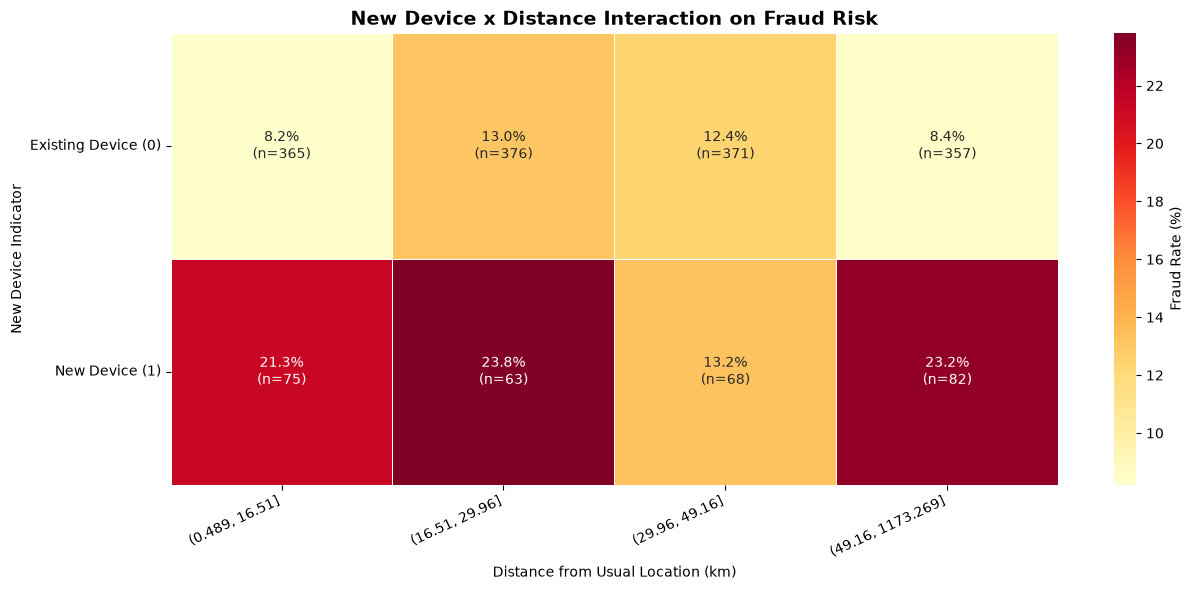

In [62]:
# ============================================================
# SECTION B - ADVANCED EDA
# Cell 25: New Device x Distance Interaction
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare training data
# ------------------------------------------------------------

interaction_df = train_df[
    [
        "new_device",
        "distance_from_usual_location_km",
        "fraud"
    ]
].dropna().copy()

# ------------------------------------------------------------
# Step 2: Create distance quantiles
# ------------------------------------------------------------

interaction_df["distance_group"] = pd.qcut(
    interaction_df["distance_from_usual_location_km"],
    q=4,
    duplicates="drop"
)

# ------------------------------------------------------------
# Step 3: Calculate interaction statistics
# ------------------------------------------------------------

interaction_analysis = (
    interaction_df.groupby(
        ["new_device", "distance_group"],
        observed=True
    )["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

interaction_analysis["fraud_rate"] *= 100

print("=" * 70)
print("NEW DEVICE x DISTANCE INTERACTION ANALYSIS")
print("=" * 70)

display(interaction_analysis.round(2))

# ------------------------------------------------------------
# Step 4: Create pivot tables
# ------------------------------------------------------------

fraud_pivot = interaction_analysis.pivot(
    index="new_device",
    columns="distance_group",
    values="fraud_rate"
)

count_pivot = interaction_analysis.pivot(
    index="new_device",
    columns="distance_group",
    values="total_transactions"
)

# ------------------------------------------------------------
# Step 5: Build annotations with fraud rate and sample size
# ------------------------------------------------------------

annotations = fraud_pivot.copy().astype(object)

for row in fraud_pivot.index:

    for col in fraud_pivot.columns:

        rate = fraud_pivot.loc[row, col]
        count = count_pivot.loc[row, col]

        if pd.notna(rate) and pd.notna(count):

            annotations.loc[row, col] = (
                f"{rate:.1f}%\n(n={int(count)})"
            )

        else:
            annotations.loc[row, col] = ""

# ------------------------------------------------------------
# Step 6: Heatmap
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

sns.heatmap(
    fraud_pivot,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={
        "label": "Fraud Rate (%)"
    }
)

plt.title(
    "New Device x Distance Interaction on Fraud Risk",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Distance from Usual Location (km)")
plt.ylabel("New Device Indicator")

plt.yticks(
    ticks=[0.5, 1.5],
    labels=["Existing Device (0)", "New Device (1)"],
    rotation=0
)

plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

TRANSACTION AMOUNT x MERCHANT RISK ANALYSIS


,amount_group,merchant_risk_group,total_transactions,fraud_transactions,fraud_rate
0,Low,Low,195,17,8.72
1,Low,Medium,182,15,8.24
2,Low,High,202,32,15.84
3,Medium,Low,201,22,10.95
4,Medium,Medium,190,15,7.89
5,Medium,High,187,25,13.37
6,High,Low,184,26,14.13
7,High,Medium,208,30,14.42
8,High,High,186,34,18.28


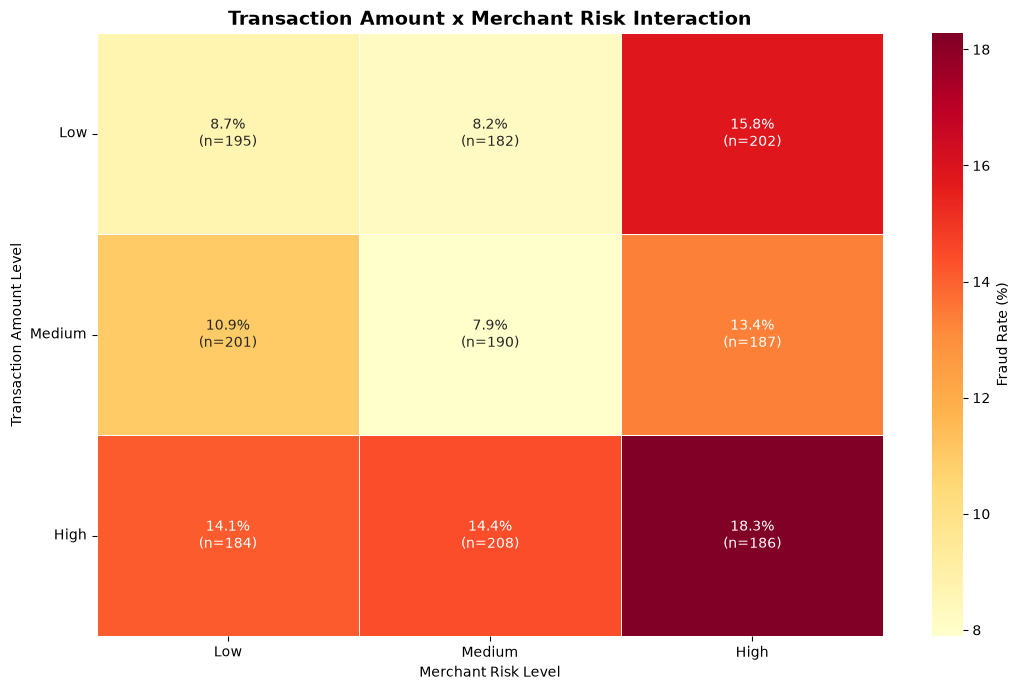


Total Transactions Analyzed: 1735


In [63]:
# ============================================================
# SECTION B - ADVANCED EDA
# Cell 26: Transaction Amount x Merchant Risk Interaction
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare training data
# ------------------------------------------------------------

amount_risk_df = train_df[
    [
        "transaction_amount",
        "merchant_risk_score",
        "fraud"
    ]
].dropna().copy()

# ------------------------------------------------------------
# Step 2: Create transaction amount groups
# ------------------------------------------------------------

amount_risk_df["amount_group"] = pd.qcut(
    amount_risk_df["transaction_amount"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# ------------------------------------------------------------
# Step 3: Create merchant risk groups
# ------------------------------------------------------------

amount_risk_df["merchant_risk_group"] = pd.qcut(
    amount_risk_df["merchant_risk_score"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# ------------------------------------------------------------
# Step 4: Calculate interaction statistics
# ------------------------------------------------------------

amount_risk_analysis = (
    amount_risk_df.groupby(
        ["amount_group", "merchant_risk_group"],
        observed=True
    )["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

amount_risk_analysis["fraud_rate"] *= 100

print("=" * 70)
print("TRANSACTION AMOUNT x MERCHANT RISK ANALYSIS")
print("=" * 70)

display(amount_risk_analysis.round(2))

# ------------------------------------------------------------
# Step 5: Create pivot tables
# ------------------------------------------------------------

fraud_pivot = amount_risk_analysis.pivot(
    index="amount_group",
    columns="merchant_risk_group",
    values="fraud_rate"
)

count_pivot = amount_risk_analysis.pivot(
    index="amount_group",
    columns="merchant_risk_group",
    values="total_transactions"
)

# ------------------------------------------------------------
# Step 6: Create heatmap annotations
# ------------------------------------------------------------

annotations = fraud_pivot.copy().astype(object)

for row in fraud_pivot.index:

    for col in fraud_pivot.columns:

        rate = fraud_pivot.loc[row, col]
        count = count_pivot.loc[row, col]

        if pd.notna(rate) and pd.notna(count):

            annotations.loc[row, col] = (
                f"{rate:.1f}%\n(n={int(count)})"
            )

        else:
            annotations.loc[row, col] = ""

# ------------------------------------------------------------
# Step 7: Visualization
# ------------------------------------------------------------

plt.figure(figsize=(11, 7))

sns.heatmap(
    fraud_pivot,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={
        "label": "Fraud Rate (%)"
    }
)

plt.title(
    "Transaction Amount x Merchant Risk Interaction",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Merchant Risk Level")
plt.ylabel("Transaction Amount Level")

plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("\nTotal Transactions Analyzed:", len(amount_risk_df))

AUTHENTICATION LEVEL x CHANNEL ANALYSIS


,authentication_level,channel,total_transactions,fraud_transactions,fraud_rate
0,Missing,ATM,18,2,11.11
1,Missing,E-commerce,59,16,27.12
2,Missing,Mobile App,33,8,24.24
3,Missing,POS,51,7,13.73
4,Standard,ATM,65,7,10.77
5,Standard,E-commerce,330,45,13.64
6,Standard,Mobile App,170,20,11.76
7,Standard,POS,254,28,11.02
8,Strong,ATM,80,7,8.75
9,Strong,E-commerce,320,39,12.19


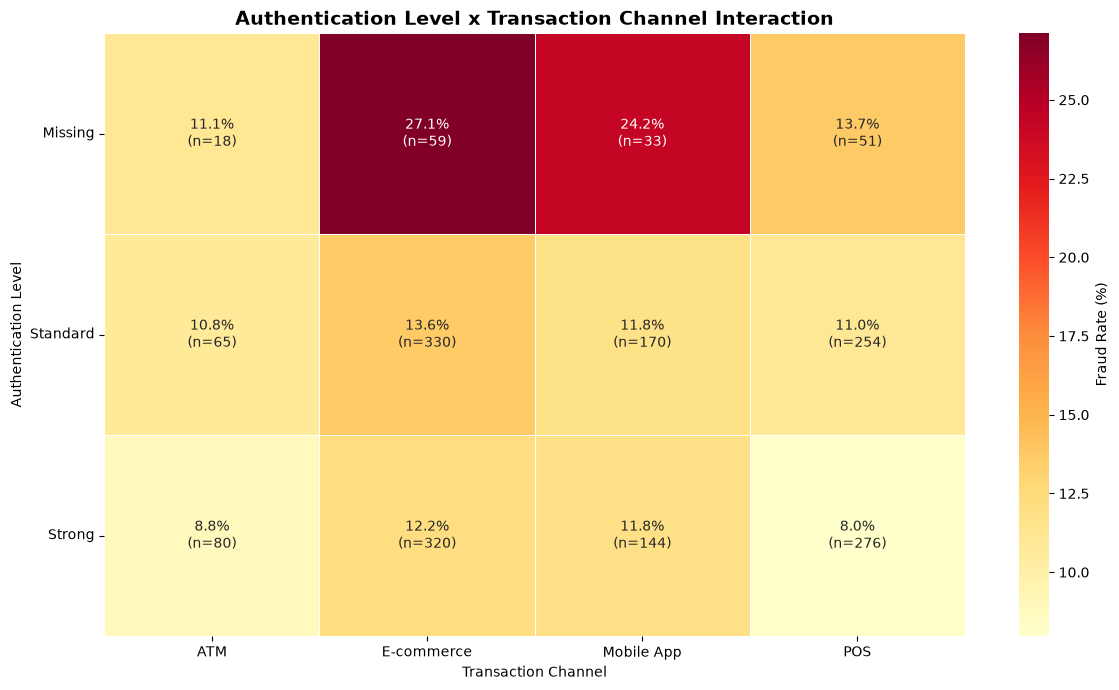

In [64]:
# ============================================================
# SECTION B - ADVANCED EDA
# Cell 27: Authentication Level x Transaction Channel
# ============================================================

# ------------------------------------------------------------
# Step 1: Prepare training data
# ------------------------------------------------------------

auth_channel_df = train_df[
    [
        "authentication_level",
        "channel",
        "fraud"
    ]
].copy()

# Preserve missing authentication values
auth_channel_df["authentication_level"] = (
    auth_channel_df["authentication_level"]
    .fillna("Missing")
)

# ------------------------------------------------------------
# Step 2: Calculate interaction statistics
# ------------------------------------------------------------

auth_channel_analysis = (
    auth_channel_df.groupby(
        ["authentication_level", "channel"]
    )["fraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .reset_index()
)

auth_channel_analysis["fraud_rate"] *= 100

print("=" * 70)
print("AUTHENTICATION LEVEL x CHANNEL ANALYSIS")
print("=" * 70)

display(auth_channel_analysis.round(2))

# ------------------------------------------------------------
# Step 3: Create pivot tables
# ------------------------------------------------------------

fraud_pivot = auth_channel_analysis.pivot(
    index="authentication_level",
    columns="channel",
    values="fraud_rate"
)

count_pivot = auth_channel_analysis.pivot(
    index="authentication_level",
    columns="channel",
    values="total_transactions"
)

# Arrange authentication levels
auth_order = [
    "Missing",
    "Standard",
    "Strong"
]

fraud_pivot = fraud_pivot.reindex(auth_order)

count_pivot = count_pivot.reindex(auth_order)

# ------------------------------------------------------------
# Step 4: Prepare annotations
# ------------------------------------------------------------

annotations = fraud_pivot.copy().astype(object)

for row in fraud_pivot.index:

    for col in fraud_pivot.columns:

        rate = fraud_pivot.loc[row, col]
        count = count_pivot.loc[row, col]

        if pd.notna(rate) and pd.notna(count):

            annotations.loc[row, col] = (
                f"{rate:.1f}%\n(n={int(count)})"
            )

        else:
            annotations.loc[row, col] = ""

# ------------------------------------------------------------
# Step 5: Visualization
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

sns.heatmap(
    fraud_pivot,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={
        "label": "Fraud Rate (%)"
    }
)

plt.title(
    "Authentication Level x Transaction Channel Interaction",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Transaction Channel")
plt.ylabel("Authentication Level")

plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

NUMERICAL FEATURE CORRELATION ANALYSIS

Numerical Features:
['hour', 'day_of_week', 'transaction_amount', 'distance_from_usual_location_km', 'transactions_last_1h', 'transactions_last_24h', 'account_age_days', 'failed_logins_24h', 'prior_chargebacks', 'device_age_days', 'merchant_risk_score', 'ip_risk_score', 'email_age_days', 'login_to_transaction_minutes', 'new_device', 'billing_address_mismatch', 'fraud']

Feature Correlation with Fraud:


,feature,spearman_correlation
0,new_device,0.1109
1,transactions_last_1h,0.0969
2,transactions_last_24h,0.0730
3,prior_chargebacks,0.0646
4,merchant_risk_score,0.0640
5,ip_risk_score,0.0561
6,transaction_amount,0.0548
7,account_age_days,-0.0536
8,login_to_transaction_minutes,-0.0515
9,billing_address_mismatch,0.0457


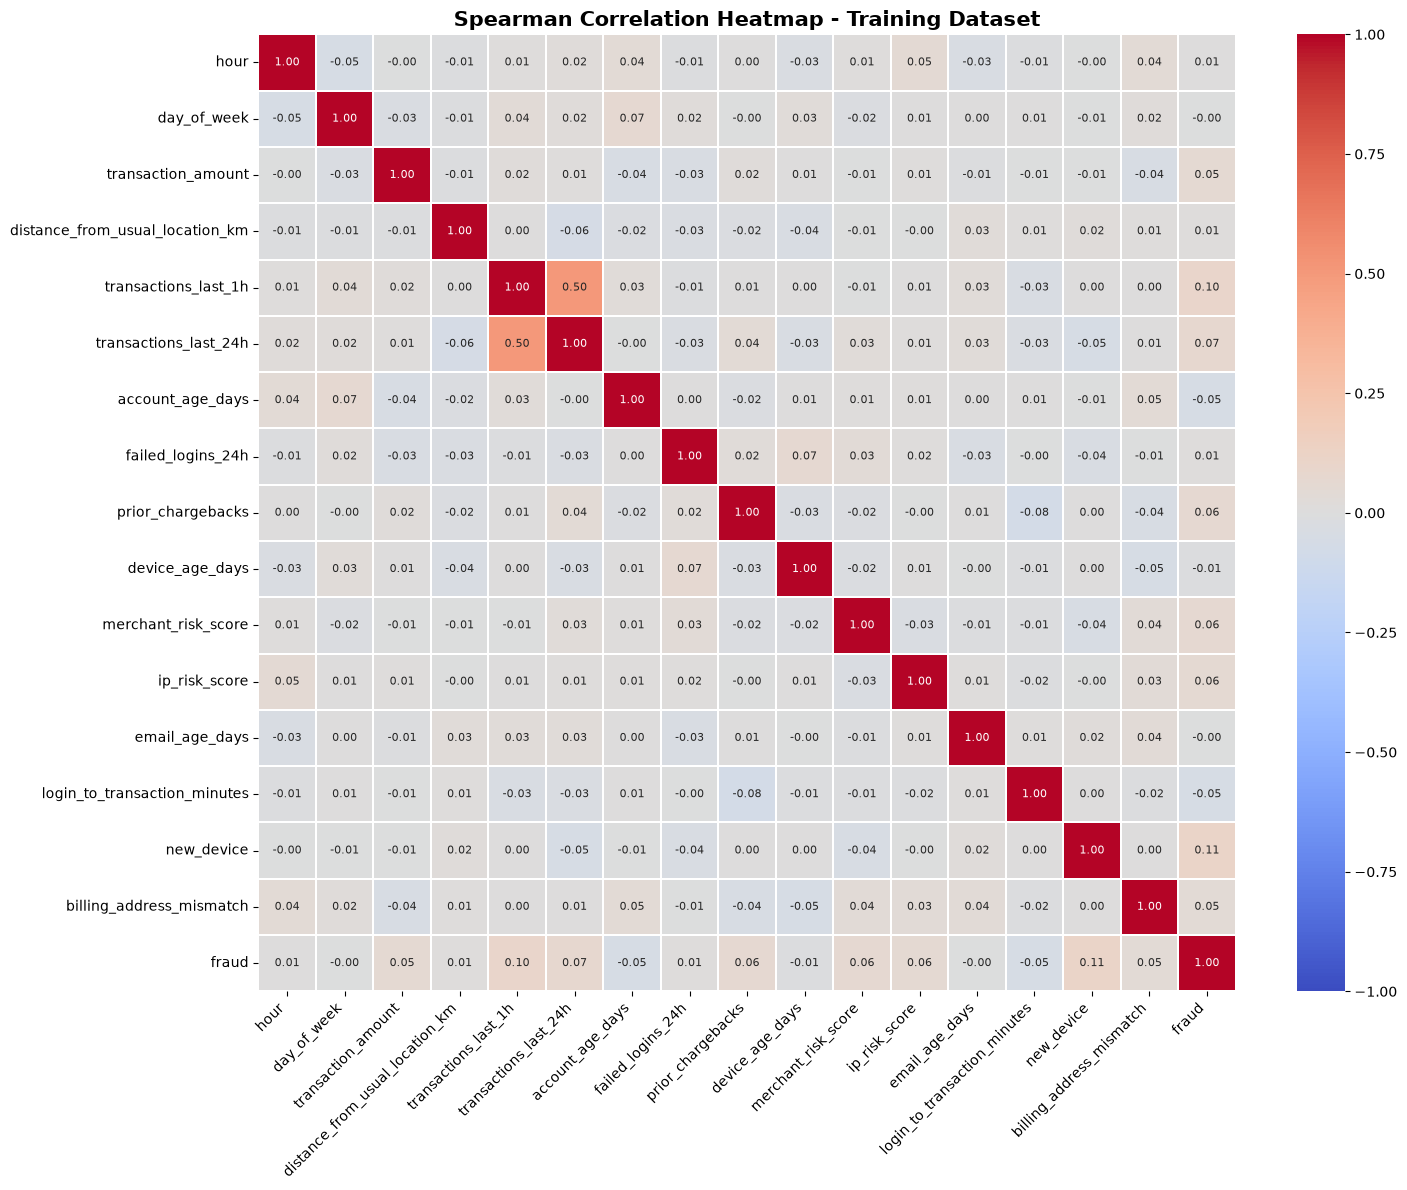


Top 10 Numerical Features by Absolute
Correlation with Fraud:


,feature,spearman_correlation
0,new_device,0.1109
1,transactions_last_1h,0.0969
2,transactions_last_24h,0.0730
3,prior_chargebacks,0.0646
4,merchant_risk_score,0.0640
5,ip_risk_score,0.0561
6,transaction_amount,0.0548
7,account_age_days,-0.0536
8,login_to_transaction_minutes,-0.0515
9,billing_address_mismatch,0.0457


In [65]:
# ============================================================
# SECTION B - ADVANCED EDA
# Cell 28: Numerical Feature Correlation Analysis
# ============================================================

# ------------------------------------------------------------
# Step 1: Select numerical features
# ------------------------------------------------------------

numeric_df = train_df.select_dtypes(
    include=[np.number]
).copy()

# Exclude identifiers if present
numeric_df = numeric_df.drop(
    columns=["transaction_id"],
    errors="ignore"
)

print("=" * 70)
print("NUMERICAL FEATURE CORRELATION ANALYSIS")
print("=" * 70)

print("\nNumerical Features:")
print(numeric_df.columns.tolist())

# ------------------------------------------------------------
# Step 2: Calculate Spearman correlation
# ------------------------------------------------------------

correlation_matrix = numeric_df.corr(
    method="spearman"
)

# ------------------------------------------------------------
# Step 3: Fraud target correlations
# ------------------------------------------------------------

fraud_correlations = (
    correlation_matrix["fraud"]
    .drop("fraud")
    .sort_values(
        key=lambda x: x.abs(),
        ascending=False
    )
)

fraud_correlation_df = (
    fraud_correlations
    .reset_index()
)

fraud_correlation_df.columns = [
    "feature",
    "spearman_correlation"
]

print("\nFeature Correlation with Fraud:")

display(fraud_correlation_df.round(4))

# ------------------------------------------------------------
# Step 4: Correlation heatmap
# ------------------------------------------------------------

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot_kws={
        "size": 8
    }
)

plt.title(
    "Spearman Correlation Heatmap - Training Dataset",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Step 5: Display top correlations
# ------------------------------------------------------------

print("\nTop 10 Numerical Features by Absolute")
print("Correlation with Fraud:")

display(
    fraud_correlation_df.head(10).round(4)
)

In [66]:
# ============================================================
# SECTION B - ADVANCED EXPLORATORY DATA ANALYSIS
# Cell 29: Generate Advanced EDA Report
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# Step 1: Define report directory
# ------------------------------------------------------------

REPORT_DIR = PROJECT_ROOT / "reports"

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

REPORT_PATH = (
    REPORT_DIR / "02_advanced_eda_report.md"
)

# ------------------------------------------------------------
# Step 2: Markdown table helper
# ------------------------------------------------------------

def eda_to_markdown(dataframe):

    df_temp = dataframe.copy()

    headers = df_temp.columns.tolist()

    header_line = (
        "| " + " | ".join(headers) + " |"
    )

    separator = (
        "| " + " | ".join(
            ["---"] * len(headers)
        ) + " |"
    )

    rows = []

    for row in df_temp.itertuples(
        index=False,
        name=None
    ):

        values = [
            str(value).replace("|", "\\|")
            for value in row
        ]

        rows.append(
            "| " + " | ".join(values) + " |"
        )

    return "\n".join(
        [header_line, separator] + rows
    )


# ------------------------------------------------------------
# Step 3: Prepare summary statistics
# ------------------------------------------------------------

training_transactions = len(train_df)

training_fraud = int(
    train_df["fraud"].sum()
)

training_legitimate = (
    training_transactions - training_fraud
)

training_fraud_rate = (
    train_df["fraud"].mean() * 100
)

top_correlations = (
    fraud_correlation_df.head(10).round(4)
)

# ------------------------------------------------------------
# Step 4: Generate report
# ------------------------------------------------------------

report = f"""
# Fraud Risk Intelligence
# Advanced Exploratory Data Analysis Report

## 1. Executive Summary

This report presents the advanced exploratory
data analysis performed on the fraud transaction
training dataset.

The primary objective is to investigate fraud
patterns, nonlinear relationships, and feature
interactions before model development.

The analysis uses the training subset to reduce
the risk of using final-test information for
feature engineering decisions.

## 2. Training Dataset Overview

- Total training transactions: {training_transactions}
- Fraudulent transactions: {training_fraud}
- Legitimate transactions: {training_legitimate}
- Overall fraud rate: {training_fraud_rate:.2f}%

The dataset exhibits class imbalance.

Evaluation should prioritize PR-AUC, recall,
precision, calibration, and business cost,
rather than accuracy alone.

## 3. Fraud Rate by Transaction Channel

{eda_to_markdown(channel_analysis.round(2))}

### Findings

Transaction channels exhibit different
observed fraud rates.

Channel information may provide useful
predictive information.

The relationship is observational and
does not establish causality.

## 4. Fraud Rate by Merchant Category

{eda_to_markdown(merchant_analysis.round(2))}

### Findings

Merchant categories exhibit variation
in observed fraud rates.

Sample sizes should be considered
when interpreting category-level differences.

## 5. Fraud Rate by Customer Tier

{eda_to_markdown(tier_analysis.round(2))}

### Findings

Customer tiers exhibit differences
in fraud rates.

Customer tier alone should not be used
to justify adverse transaction decisions.

## 6. Fraud Rate by Device Type

{eda_to_markdown(device_analysis.round(2))}

### Findings

Fraud rates across device types are
relatively similar.

Device type may still contribute through
interactions with other transaction features.

## 7. Transaction Amount Analysis

{eda_to_markdown(amount_analysis.round(2))}

### Findings

The highest transaction amount quantile
exhibits elevated fraud risk.

The relationship is not strictly monotonic,
suggesting potential nonlinear effects.

## 8. Transaction Velocity Analysis

{eda_to_markdown(velocity_analysis.round(2))}

### Findings

Higher transaction velocity groups
show elevated observed fraud rates.

The highest velocity group has a
small sample size.

Therefore, its estimated fraud rate
should be interpreted cautiously.

## 9. Distance Analysis

{eda_to_markdown(distance_analysis.round(2))}

### Findings

Distance does not show a consistently
increasing fraud rate across quantiles.

Distance may be more informative when
combined with device-related indicators.

## 10. Account Age Analysis

{eda_to_markdown(account_age_analysis.round(2))}

### Findings

Older account groups generally exhibit
lower observed fraud rates.

The relationship is not strictly monotonic.

## 11. Merchant Risk Score Analysis

{eda_to_markdown(
    risk_analysis_results["merchant_risk_score"].round(2)
)}

### Findings

Higher merchant risk score quantiles
generally show elevated fraud rates.

## 12. IP Risk Score Analysis

{eda_to_markdown(
    risk_analysis_results["ip_risk_score"].round(2)
)}

### Findings

The highest IP risk score quantile
exhibits elevated fraud risk.

## 13. New Device and Distance Interaction

{eda_to_markdown(interaction_analysis.round(2))}

### Findings

New-device transactions exhibit higher
fraud rates across the analyzed
distance groups.

The magnitude of the difference varies
across groups.

These results suggest potential
interaction effects requiring
model-based verification.

## 14. Transaction Amount and Merchant Risk Interaction

{eda_to_markdown(amount_risk_analysis.round(2))}

### Findings

The combination of high transaction amount
and high merchant risk exhibits elevated
observed fraud risk.

Both features should be evaluated individually
and through interaction features.

## 15. Authentication Level and Channel Interaction

{eda_to_markdown(auth_channel_analysis.round(2))}

### Findings

Missing authentication information in
E-commerce and Mobile App transactions
is associated with elevated observed fraud rates.

Missingness indicators and channel interactions
should be evaluated during feature engineering.

## 16. Spearman Correlation Analysis

### Top Numerical Correlations With Fraud

{eda_to_markdown(top_correlations)}

### Findings

Individual numerical feature correlations
with the fraud target are generally weak.

New-device and transaction-velocity indicators
show some of the largest observed
absolute correlations.

Weak marginal correlations do not imply
that nonlinear models or interactions
will be ineffective.

Correlation does not establish causation.

## 17. Feature Engineering Recommendations

The following candidate features will be
investigated in the next project phase:

1. velocity_ratio
2. hourly_velocity_intensity
3. transaction_amount_log
4. amount_merchant_risk_interaction
5. new_device_distance_interaction
6. combined_risk_score
7. authentication_level_missing
8. authentication_channel_interaction
9. account_device_age_ratio
10. failed_login_ip_risk
11. billing_device_interaction
12. high_velocity_indicator

These features are hypotheses derived
from exploratory analysis.

Their usefulness must be measured through
leakage-safe cross-validation and
comparison with baseline features.

## 18. Limitations

- The dataset contains only 3,000 transactions.
- Some subgroup analyses have small sample sizes.
- Full transaction timestamps are unavailable.
- Customer identifiers are unavailable.
- True chronological validation is not possible.
- Several historical and risk-related features
  require prediction-time availability checks.
- Earlier preliminary audits examined the full
  dataset, limiting claims of a completely
  unseen test set.
- Observed associations are not causal evidence.
- Correlation analysis does not capture all
  nonlinear relationships or interactions.

## 19. Next Steps

The next development phase is Feature Engineering.

The implementation will:

- Create at least 10 derived features.
- Preserve original data.
- Avoid target-derived leakage.
- Use prediction-time available information.
- Compare models with and without
  engineered features.
- Evaluate feature stability and robustness.

## 20. Conclusion

The exploratory analysis identified several
potential fraud-risk signals involving
transaction velocity, transaction amount,
new-device activity, risk scores,
and authentication missingness.

Multiple feature interactions were observed.

These findings motivate the development
of nonlinear classification models and
defensible engineered features.

Final predictive usefulness must be established
using appropriate training, validation,
and business-cost evaluation.

## Visualization Reference

The accompanying Jupyter notebook contains
the detailed EDA visualizations and
corresponding statistical tables.

Notebook:
../notebooks/01_fraud_risk_analysis.ipynb
"""

# ------------------------------------------------------------
# Step 5: Save report
# ------------------------------------------------------------

REPORT_PATH.write_text(
    report.strip() + "\n",
    encoding="utf-8"
)

print("=" * 70)
print("ADVANCED EDA REPORT GENERATED")
print("=" * 70)

print("\nReport Location:")
print(REPORT_PATH)

print("\nTraining Transactions:", training_transactions)
print("Training Fraud Cases:", training_fraud)

print("\nReport generated successfully!")

ADVANCED EDA REPORT GENERATED

Report Location:
e:\fraud-risk-intelligence\fraud-risk-intelligence\reports\02_advanced_eda_report.md

Training Transactions: 1800
Training Fraud Cases: 218

Report generated successfully!
